<a href="https://colab.research.google.com/github/Muzanni23/Komparasi-Model-ConvNeXt-DeiT-III-dan-Swin-V2-Dataset-InaTR/blob/main/UAS_ACV_InaTRC_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UAS Advanced Computer Vision — InaTRC
## Perbandingan ConvNeXt, DeiT III, dan Swin V2 pada Klasifikasi Golongan Kendaraan Gerbang Tol pada Dataset InaTRC

**Pertanyaan penelitian:** di antara tiga arsitektur modern (CNN modern, ViT, dan ViT hierarkis) yang di-*fine-tune* dengan resep yang sama, mana yang paling baik mengenali golongan kendaraan tol, dan apakah pembobotan kelas membantu golongan yang langka?

**Jenis kontribusi:** evaluasi komparatif (model dan dataset sudah ada; rancangan percobaan, hasil, dan analisisnya milik kita). Jangan menulis "metode baru".

### Temuan desain: kebocoran temporal pada split resmi
Gambar InaTRC adalah frame CCTV bernomor berurutan yang dibagi **acak** ke train/val/test. Frame bertetangga hampir sama (kendaraan yang sama tampak di beberapa frame berturut-turut), sehingga kendaraan yang sama dapat berada di train **dan** test. Bagian 3 mengukur hal ini dengan data. Karena itu notebook ini memakai **dua protokol evaluasi**:

| Protokol | Cara membagi data | Peran |
|---|---|---|
| **blok** | Gambar dikelompokkan menjadi blok berurutan (±40 frame); blok utuh dialokasikan ke train/val/test, dengan zona penyangga di antaranya | **Protokol utama**: perkiraan kinerja yang jujur pada kendaraan yang belum pernah dilihat |
| **resmi** | Split resmi dari penyedia dataset | Pembanding agar hasil dapat dikaitkan dengan dataset aslinya; berpotensi mengandung kebocoran temporal (diuji di Bagian 12h) |

### Cara memakai (urut dari atas ke bawah)
1. **Runtime → Change runtime type → T4 GPU.**
2. Siapkan **zip dataset InaTRC** (file dari Mendeley). Pilih salah satu: (a) *drag & drop* zip ke panel file Colab (`/content`), atau (b) simpan zip di folder proyek di Google Drive (folder yang sama dengan notebook ini). Jika keduanya belum, Bagian 2 membuka jendela pilih-file.
3. Jalankan sel satu per satu (atau **Run all**). Tiap bagian punya *checkpoint* dan penjelasan **cara membaca hasil**.
4. **Semua hasil disimpan langsung di folder proyek Google Drive** (folder yang sama dengan notebook ini): tabel CSV, gambar, subfolder `blok/` dan `resmi/` (hasil per protokol), dan `runs/` (hasil tiap training).
5. **Mulai bersih:** jika folder proyek berisi hasil dari versi notebook lain, hasil itu **dipindahkan** (tidak dihapus) ke `arsip_hasil_lama_<waktu>/` dan training dimulai dari nol.
6. **Jika Colab terputus**, buka lagi dan **Run all**: run yang sudah selesai dilewati otomatis (hanya run yang terputus di tengah yang diulang).

### Perkiraan waktu (T4)
Dari uji sebelumnya: ConvNeXt-T ±18 menit/run, DeiT3-S ±12 menit/run, SwinV2-T ±40 menit/run. Fase 1 satu protokol (3 model × 3 seed) ±3,5 jam; Fase 2 ±1–2 jam; protokol kedua (resmi) ±3,5 jam. **Total ±8–9 jam.** Urutannya dibuat agar hasil terpenting selesai lebih dulu: Fase 1 blok → Fase 2 blok → Fase 1 resmi. Bagian 8 mencetak estimasi yang tepat untuk GPU yang Anda dapat.

### Peta isi
| Bagian | Isi |
|---|---|
| 1–2 | Setup, konfigurasi, memuat dataset, arsip hasil lama |
| 3 | Tabel box, **audit kebocoran temporal**, pembuatan **split blok** |
| 4–5 | Crop per kendaraan, ukuran crop, pemeriksaan visual |
| 6 | Baseline "hanya ukuran box" |
| 7–8 | Data ke memori, uji kecepatan (estimasi waktu) |
| 9–10 | Fungsi training; Fase 1 (3 model, loss biasa) dan Fase 2 (pembobotan kelas) |
| 11–12 | Tabel hasil; analisis (interval kepercayaan, confusion matrix, laporan per golongan, ukuran crop, grafik, galeri salah prediksi, latensi, dampak kebocoran) |
| 13 | Ringkasan otomatis dan interpretasi |
| 14 | Pencatatan lingkungan, ekspor, kerangka laporan dan slide 10 menit |

**Pemetaan kelas:** `cls_id` 0–4 pada label = Golongan 1–5 (`golongan = cls_id + 1`). Diverifikasi secara visual di Bagian 5.

## 1. Setup dan konfigurasi
Semua pengaturan penting ada di sel konfigurasi. **Resep training sama untuk ketiga model** (optimizer, learning rate, epoch, augmentasi) supaya perbedaan hasil berasal dari arsitekturnya, bukan dari pengaturan. Resep ini tidak di-*tuning* per model; itu keterbatasan yang harus ditulis di laporan.

**Jangan mengubah `EPOCHS`, `SEEDS`, `LR`, `WD`, `BATCH`, `BLOCK_IMG`, `BUFFER_IMG`, `SPLIT_SEED` setelah training dimulai.** Notebook menolak melanjutkan jika konfigurasi run lama berbeda.

In [1]:
import sys, subprocess, importlib
def ensure(pkg, mod=None):
    try:
        importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
ensure("timm")

import os, random, zipfile, shutil, json, time, math, datetime, platform
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import timm, sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

# ----------------------------- KONFIGURASI -----------------------------
NOTEBOOK_VERSI = "v3"
DEBUG = False            # True = uji cepat (data sangat kecil, 1-2 epoch). Untuk hasil sebenarnya: False.
DEBUG_PER_CLASS = 12

USE_DRIVE = True         # True = hasil disimpan ke Google Drive (aman jika Colab terputus)
UPLOAD_DIR = Path("/content")
WORK = Path("/content/inatrc")                      # folder kerja lokal (ekstrak dataset dan crop)
# Folder hasil = folder yang sama dengan notebook ini di Google Drive ("Drive Saya" = /content/drive/MyDrive)
DRIVE_PARENT = Path("/content/drive/MyDrive/UNPAM/Advance Computer Vision")
FOLDER_NAME  = "Perbandingan ConvNeXt, DeiT III, dan Swin V2 pada Klasifikasi Golongan Kendaraan Gerbang Tol pada Dataset InaTRC - Ahmad Muzanni_251012000041"
OUT  = DRIVE_PARENT / FOLDER_NAME if USE_DRIVE else Path("/content/hasil")

SEED   = 42              # seed umum (sampling, bootstrap)
SEEDS  = [0, 1, 2]       # seed training: tiap model dilatih 3x
EPOCHS = 8
BATCH  = 64
LR     = 1e-4
WD     = 0.05
PAD_FRAC = 0.0           # konteks tambahan di sekeliling box (0.0 = tanpa)
MIN_SIDE = 0             # buang crop dengan sisi pendek < MIN_SIDE px (0 = tidak membuang). Diputuskan di Bagian 4.

# Protokol evaluasi. Urutan = prioritas; yang pertama adalah protokol UTAMA (mendapat Fase 2 dan analisis penuh).
PROTOKOL   = ["blok", "resmi"]     # isi ["blok"] saja jika waktu tidak cukup untuk protokol pembanding
BLOCK_IMG  = 40          # jumlah frame berurutan per blok (blok utuh dialokasikan ke satu split)
BUFFER_IMG = 10          # zona penyangga: frame train/val dalam jarak segini dari split lain dibuang (±20 detik)
SPLIT_SEED = 2026        # seed pengacakan alokasi blok (tetap, agar split dapat direproduksi)
N_TRIAL_SPLIT = 20000    # banyaknya alokasi acak yang dicoba; dipilih yang proporsi kelasnya paling mendekati 80/10/10
BOOT_B = 1000            # resampel bootstrap
BOOT_FRAMES = 10         # bootstrap per kelompok BOOT_FRAMES frame berurutan (frame bertetangga saling berkorelasi, jadi bukan per gambar)

# Tiga model, semuanya pra-latih ImageNet-1k (supervised) agar pra-latihannya setara.
MODELS = {
    "ConvNeXt-T": dict(name="convnext_tiny.fb_in1k"),                # CNN modern (Liu dkk., CVPR 2022)
    "DeiT3-S":    dict(name="deit3_small_patch16_224.fb_in1k"),      # ViT dengan resep latih baru (Touvron dkk., ECCV 2022)
    "SwinV2-T":   dict(name="swinv2_tiny_window8_256.ms_in1k"),      # ViT hierarkis (Liu dkk., CVPR 2022)
}

# Angka dari audit data (jumlah BOX dan GAMBAR per split resmi). Notebook berhenti jika tidak cocok.
EXPECTED        = {"train": 27063, "val": 3703, "test": 3642}
EXPECTED_IMAGES = {"train": 2600,  "val": 325,  "test": 325}
# -----------------------------------------------------------------------

COL = {"resmi": "split", "blok": "split_blok"}      # kolom penentu split untuk tiap protokol
assert len(PROTOKOL) >= 1 and set(PROTOKOL) <= set(COL) and len(set(PROTOKOL)) == len(PROTOKOL), "PROTOKOL harus berisi 'blok' dan/atau 'resmi'"
UTAMA = PROTOKOL[0]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = dev.type == "cuda"
print("torch", torch.__version__, "| timm", timm.__version__, "| device:", dev,
      (torch.cuda.get_device_name(0) if use_amp else ""))
print("Protokol:", PROTOKOL, "| utama:", UTAMA)
if not DEBUG:
    assert use_amp, "GPU tidak aktif. Runtime > Change runtime type > T4 GPU, lalu jalankan ulang."

torch 2.14.1+cu130 | timm 1.0.31 | device: cuda Tesla T4
Protokol: ['blok', 'resmi'] | utama: blok


## 2. Memuat dataset
Sel di bawah (1) me-*mount* Google Drive, (2) **mengarsipkan hasil lama** jika folder proyek berisi hasil dari versi notebook lain (dipindahkan, **tidak dihapus**), dan (3) mencari zip dataset di `/content`, lalu di folder proyek. Jika tidak ada, jendela pilih-file akan muncul. Zip diekstrak ke folder kerja lokal (lebih cepat dari Drive).

Penanda `runs/_protokol.json` menandai bahwa folder hasil dibuat oleh notebook versi ini. Selama penanda cocok, menjalankan ulang notebook = **melanjutkan** (run yang selesai dilewati). Hasil tanpa penanda yang cocok selalu diarsipkan, sehingga tidak ada hasil lama yang tercampur.

In [2]:
if USE_DRIVE:
    from google.colab import drive      # COLAB-ONLY
    drive.mount("/content/drive")       # COLAB-ONLY
    if not OUT.parent.exists():         # cegah folder kembar akibat salah ketik nama folder induk
        up = OUT.parent.parent
        raise FileNotFoundError(f"Folder induk tidak ditemukan: {OUT.parent}\n"
                                f"Isi {up}: {sorted(p.name for p in up.glob('*')) if up.exists() else '(folder tidak ada)'}\n"
                                f"Perbaiki DRIVE_PARENT di Bagian 1 agar sama persis dengan nama folder di Drive Anda.")
    print("Folder hasil:", OUT, "| sudah ada:", OUT.exists())
OUT.mkdir(parents=True, exist_ok=True)
RES = OUT / "runs"
MARKER = RES / "_protokol.json"
WORK.mkdir(parents=True, exist_ok=True)

# ---- mulai bersih: arsipkan (pindahkan) hasil yang bukan dari notebook versi ini ----
def marker_cocok():
    try:
        return json.loads(MARKER.read_text()).get("versi") == NOTEBOOK_VERSI
    except Exception:
        return False
lama = [p for p in sorted(OUT.iterdir())
        if (p.is_dir() and p.name in {"runs", "blok", "resmi"}) or (p.is_file() and p.suffix.lower() in {".png", ".csv", ".json", ".txt"})]
if lama and not marker_cocok():
    arsip = OUT / ("arsip_hasil_lama_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"))
    arsip.mkdir()
    for p in lama:
        shutil.move(str(p), str(arsip / p.name))
    print(f"Hasil lama ({len(lama)} item) DIPINDAHKAN ke: {arsip.name}/  (tidak dihapus). Training dimulai dari nol.")
else:
    print("Melanjutkan folder hasil yang sudah ada." if lama else "Folder hasil kosong: mulai dari nol.")
RES.mkdir(exist_ok=True)
if not MARKER.exists():
    MARKER.write_text(json.dumps(dict(versi=NOTEBOOK_VERSI, dibuat=datetime.datetime.now().isoformat(timespec="seconds"))))

def find_root(base):
    c = [p.parent.parent for p in Path(base).rglob("images") if p.parent.name == "train"]
    return c[0] if len(c) == 1 else None

ROOT = find_root(WORK)                   # sudah pernah diekstrak?
if ROOT is None:
    zips = sorted(UPLOAD_DIR.glob("*.zip")) or sorted(OUT.glob("*.zip"))   # cari di /content, lalu di folder Drive proyek
    if not zips:
        print("Belum ada zip di /content maupun di folder proyek. Pilih file zip dataset InaTRC pada jendela berikut ...")
        from google.colab import files        # COLAB-ONLY
        up = files.upload()                   # COLAB-ONLY
        zips = [UPLOAD_DIR / n for n in up if n.lower().endswith(".zip")]
    assert zips, "Tidak ada file .zip yang diunggah."
    zsel = next((z for z in zips if "ina" in z.name.lower()), zips[0])
    print("Mengekstrak:", zsel.name)
    with zipfile.ZipFile(zsel) as z:
        z.extractall(WORK)
    ROOT = find_root(WORK)
assert ROOT is not None, "Struktur dataset tidak dikenali (harus ada train/images, val/images, test/images)."
print("ROOT:", ROOT)
print("Isi :", sorted(p.name for p in ROOT.iterdir()))

Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/UNPAM/Advance Computer Vision/Perbandingan ConvNeXt, DeiT III, dan Swin V2 pada Klasifikasi Golongan Kendaraan Gerbang Tol pada Dataset InaTRC - Ahmad Muzanni_251012000041 | sudah ada: True
Folder hasil kosong: mulai dari nol.
Belum ada zip di /content maupun di folder proyek. Pilih file zip dataset InaTRC pada jendela berikut ...


Saving InaTRC Indonesia Toll Road Vehicle Classification Dataset.zip to InaTRC Indonesia Toll Road Vehicle Classification Dataset.zip
Mengekstrak: InaTRC Indonesia Toll Road Vehicle Classification Dataset.zip
ROOT: /content/inatrc/InaTRC Indonesia Toll Road Vehicle Classification Dataset
Isi : ['README.md', 'test', 'train', 'val']


## 3. Tabel semua box
Dataset aslinya untuk **deteksi**: satu gambar berisi ±10 kendaraan, tiap kendaraan satu baris label YOLO (`kelas x_tengah y_tengah lebar tinggi`, ternormalisasi 0–1). Kita perlu tabel untuk mengubahnya menjadi satu baris per kendaraan.

**Cara membaca checkpoint:** jumlah box dan gambar harus **sama persis** dengan audit (27.063 / 3.703 / 3.642 box; 2.600 / 325 / 325 gambar). Distribusi kelas sangat timpang (golongan 1 ±60%, golongan 4 hanya ±1,2%); itulah alasan kita memakai **macro-F1** dan menguji pembobotan kelas.

In [3]:
SPLITS = ["train", "val", "test"]
rows = []
for sp in SPLITS:
    for lab in sorted((ROOT / sp / "labels").glob("*.txt")):
        if lab.name == "classes.txt":
            continue
        img = ROOT / sp / "images" / f"{lab.stem}.jpg"
        assert img.exists(), f"Gambar tidak ditemukan untuk label {lab}"
        for k, line in enumerate(lab.read_text().splitlines()):
            t = line.split()
            if len(t) != 5:
                continue
            rows.append(dict(split=sp, image=lab.stem, box_idx=k, cls_id=int(t[0]),
                             xc=float(t[1]), yc=float(t[2]), w=float(t[3]), h=float(t[4])))
boxes = pd.DataFrame(rows)
boxes["golongan"] = boxes["cls_id"] + 1

print(boxes.head().to_string())                                    # CHECKPOINT: contoh baris
n_box = boxes.groupby("split").size().to_dict()
n_img = boxes.groupby("split")["image"].nunique().to_dict()
print("\nBox per split   :", n_box, "| diharapkan", EXPECTED)
print("Gambar per split:", n_img, "| diharapkan", EXPECTED_IMAGES)
assert n_box == EXPECTED, "Jumlah box TIDAK cocok dengan audit -> berhenti"
assert n_img == EXPECTED_IMAGES, "Jumlah gambar TIDAK cocok dengan audit -> berhenti"
assert sorted(boxes.cls_id.unique()) == [0, 1, 2, 3, 4], "cls_id di luar 0-4"
assert boxes.groupby("image")["split"].nunique().max() == 1, "Ada nama gambar yang sama di lebih dari satu split"
try:
    boxes["img_no"] = boxes["image"].astype(int)       # nomor frame (nama berkas numerik)
except ValueError:
    raise RuntimeError("Nama gambar tidak numerik, sehingga urutan frame tidak dapat ditentukan (diperlukan untuk split blok).")
ct = pd.crosstab(boxes.split, boxes.golongan); ct["total"] = ct.sum(axis=1)
print("\nDistribusi golongan (baris = split):"); print(ct.to_string())
print("\nPersen per golongan (semua split):"); print((boxes.golongan.value_counts(normalize=True).sort_index() * 100).round(2).to_string())

   split   image  box_idx  cls_id        xc        yc         w         h  golongan
0  train  000002        0       0  0.642756  0.381250  0.021307  0.037500         1
1  train  000002        1       0  0.468040  0.413542  0.024148  0.035417         1
2  train  000002        2       1  0.417614  0.375000  0.031250  0.050000         2
3  train  000002        3       0  0.574574  0.365625  0.018466  0.031250         1
4  train  000002        4       0  0.514915  0.378125  0.021307  0.035417         1

Box per split   : {'test': 3642, 'train': 27063, 'val': 3703} | diharapkan {'train': 27063, 'val': 3703, 'test': 3642}
Gambar per split: {'test': 325, 'train': 2600, 'val': 325} | diharapkan {'train': 2600, 'val': 325, 'test': 325}

Distribusi golongan (baris = split):
golongan      1     2     3    4    5  total
split                                       
test       2131  1167   236   42   66   3642
train     16384  7683  2154  316  526  27063
val        2219  1103   262   54   65   3703


### 3b. Audit kebocoran temporal (apakah split resmi bocor?)
Nomor gambar InaTRC berlaku global (1 sampai 3.250) dan dibagi **acak** ke train/val/test. Pertanyaannya: apakah gambar bernomor berurutan adalah **adegan yang hampir sama**? Jika ya, kendaraan yang sama dapat muncul di train dan test, sehingga hasil pada split resmi berpotensi terlalu optimis (pengaruh sebenarnya diuji di Bagian 12h). Tiga bukti dihitung di bawah:
1. **Interleaving nomor:** seberapa dekat nomor gambar val/test ke gambar train terdekat.
2. **Kemiripan piksel:** selisih rata-rata thumbnail abu-abu antara gambar bernomor berurutan vs pasangan acak.
3. **Visual:** empat frame pertama berdampingan dengan cap waktu kamera.

**Cara membaca:** selisih piksel berurutan yang jauh lebih kecil dari pasangan acak, ditambah gambar val/test yang selalu bertetangga dengan gambar train, berarti kebocoran temporal nyata. Ini *bukti kemungkinan kebocoran*, bukan hitungan kendaraan duplikat (identitas kendaraan tidak dilabeli).

     image  split  n_box  img_no  rank
0   000001    val     20       1     0
1   000002  train     15       2     1
2   000003  train     15       3     2
3   000004    val     18       4     3
4   000005  train     13       5     4
5   000006    val     13       6     5
6   000007  train      8       7     6
7   000008  train      9       8     7
8   000009  train     11       9     8
9   000010  train     13      10     9
10  000011  train     11      11    10
11  000012   test     12      12    11

Nomor gambar: 1 .. 3250 | jumlah 3250 | unik 3250
val  : jarak nomor ke gambar train terdekat -> median 1, maks 3, 100% berjarak <= 2 nomor
test : jarak nomor ke gambar train terdekat -> median 1, maks 3, 99% berjarak <= 2 nomor


  0%|          | 0/300 [00:00<?, ?it/s]


Selisih piksel rata-rata (thumbnail abu-abu 48x27, 300 pasangan): nomor berurutan median 5.1 | pasangan acak median 32.8
Kesimpulan: nomor berurutan = adegan hampir sama -> kendaraan yang sama dapat muncul di train dan test pada pada split resmi (potensi kebocoran temporal; pengaruhnya pada skor diuji di Bagian 12h)


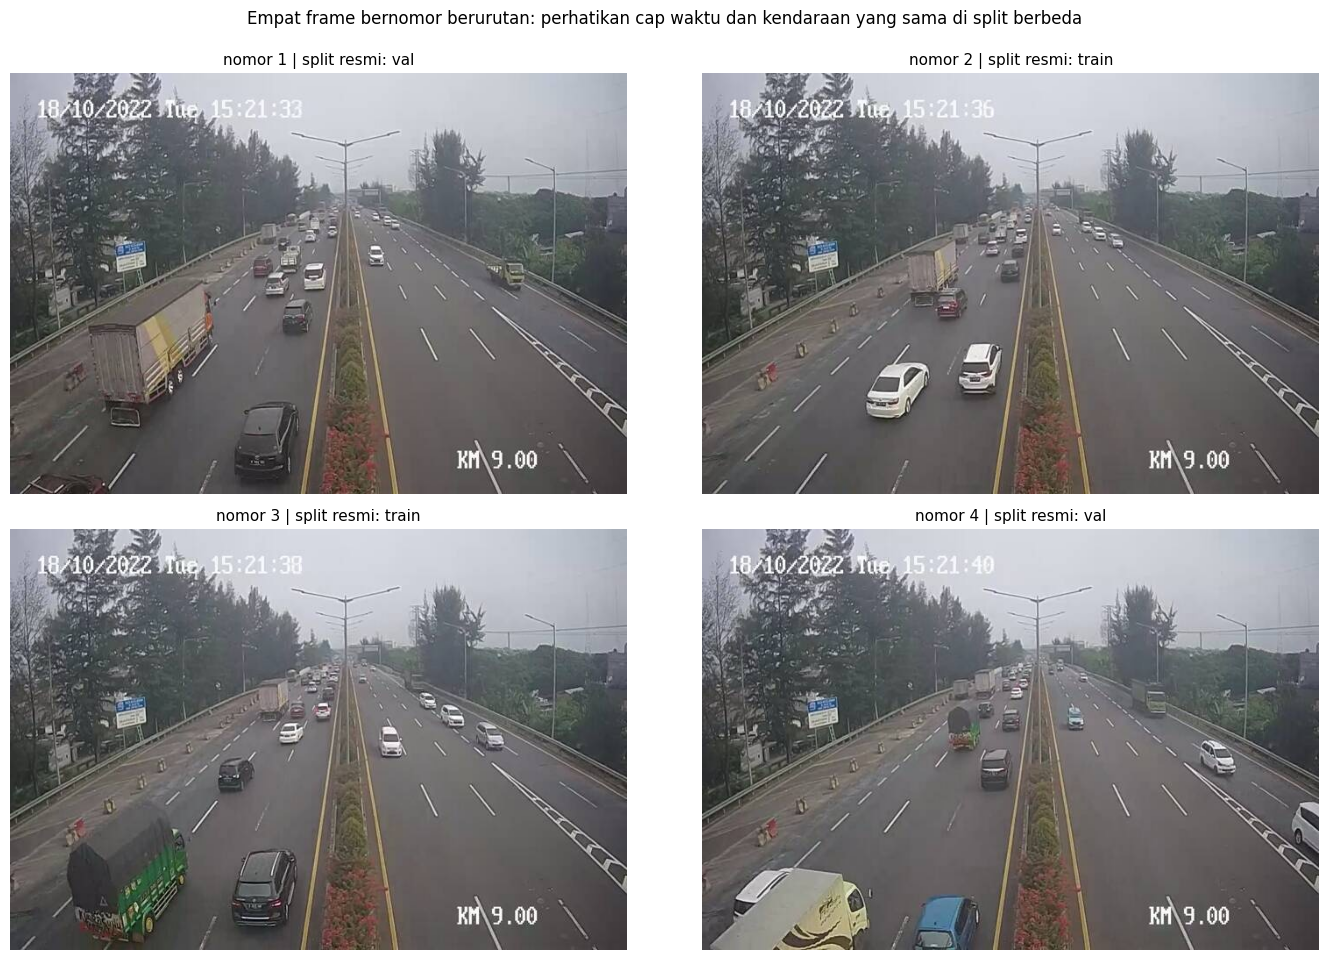

235

In [30]:
img_tab = boxes.groupby(["image", "split"]).size().rename("n_box").reset_index()
img_tab["img_no"] = img_tab["image"].astype(int)
img_tab = img_tab.sort_values("img_no").reset_index(drop=True)
img_tab["rank"] = np.arange(len(img_tab))
print(img_tab.head(12).to_string())                                    # CHECKPOINT: nomor berurutan, split acak
print(f"\nNomor gambar: {img_tab.img_no.min()} .. {img_tab.img_no.max()} | jumlah {len(img_tab)} | unik {img_tab.img_no.nunique()}")

AUDIT = {}
tr_no = img_tab.loc[img_tab.split == "train", "img_no"].values
for sp in ("val", "test"):
    q = img_tab.loc[img_tab.split == sp, "img_no"].values
    dist = np.abs(q[:, None] - tr_no[None, :]).min(axis=1)
    AUDIT[f"jarak_nomor_{sp}_median"] = float(np.median(dist)); AUDIT[f"jarak_nomor_{sp}_maks"] = int(dist.max())
    print(f"{sp:5s}: jarak nomor ke gambar train terdekat -> median {np.median(dist):.0f}, maks {dist.max()}, "
          f"{(dist <= 2).mean() * 100:.0f}% berjarak <= 2 nomor")

def thumb(r):
    im = Image.open(ROOT / r.split / "images" / f"{r.image}.jpg").convert("L").resize((48, 27))
    return np.asarray(im, np.float32)
rng_a = np.random.default_rng(SEED)
pick = rng_a.choice(len(img_tab) - 1, size=min(300, len(img_tab) - 1), replace=False)
cons, rnd = [], []
for i in tqdm(pick):
    a = thumb(img_tab.iloc[i]); b = thumb(img_tab.iloc[i + 1]); c = thumb(img_tab.iloc[int(rng_a.integers(len(img_tab)))])
    cons.append(np.abs(a - b).mean()); rnd.append(np.abs(a - c).mean())
mc, mr = float(np.median(cons)), float(np.median(rnd))
AUDIT.update(selisih_piksel_berurutan_median=mc, selisih_piksel_acak_median=mr)
print(f"\nSelisih piksel rata-rata (thumbnail abu-abu 48x27, {len(pick)} pasangan): "
      f"nomor berurutan median {mc:.1f} | pasangan acak median {mr:.1f}")
print("Kesimpulan: " + ("nomor berurutan = adegan hampir sama -> kendaraan yang sama dapat muncul di train dan test pada pada split resmi (potensi kebocoran temporal; pengaruhnya pada skor diuji di Bagian 12h)"
                        if mc < 0.5 * mr else "tidak ada bukti kuat bahwa nomor berurutan = adegan sama pada sampel ini."))

fig, axes = plt.subplots(2, 2, figsize=(14, 9.6))
for ax, (_, r) in zip(axes.ravel(), img_tab.head(4).iterrows()):
    ax.imshow(Image.open(ROOT / r.split / "images" / f"{r.image}.jpg")); ax.axis("off")
    ax.set_title(f"nomor {r.img_no} | split resmi: {r.split}", fontsize=11)
plt.suptitle("Empat frame bernomor berurutan: perhatikan cap waktu dan kendaraan yang sama di split berbeda", y=0.995)
plt.tight_layout(); plt.savefig(OUT / "audit_kebocoran_frame.png", dpi=100); plt.show()
(OUT / "audit_kebocoran.json").write_text(json.dumps(AUDIT, indent=2))

### 3c. Membuat split blok (bebas kebocoran temporal)
Prosedur (deterministik, `SPLIT_SEED` tetap):
1. Urutkan gambar menurut nomor; kelompokkan per `BLOCK_IMG` frame berurutan menjadi **blok**.
2. Coba `N_TRIAL_SPLIT` alokasi acak blok ke val dan test (±10% gambar masing-masing); pilih yang proporsi **golongan**-nya paling mendekati 10% di val dan test (supaya golongan langka tetap ada).
3. **Zona penyangga:** gambar train yang berjarak ≤ `BUFFER_IMG` frame dari val/test, dan gambar val yang berjarak ≤ `BUFFER_IMG` dari test, **dibuang**. Dengan frame ±2 detik, penyangga 10 frame ≈ 20 detik, cukup agar kendaraan yang sama tidak muncul di dua split.

**Cara membaca checkpoint:** tiap golongan harus ada di val dan test dengan jumlah memadai; jumlah gambar yang dibuang harus kecil. Split ini juga **tidak menguji generalisasi ke kamera atau hari lain** (semua blok berasal dari rekaman yang sama); itu keterbatasan yang harus ditulis.

jarak minimum antar frame train-val: 11 frame (harus > 10)
jarak minimum antar frame train-test: 11 frame (harus > 10)
jarak minimum antar frame val-test: 11 frame (harus > 10)

Blok: 82 (@40 frame) | biaya alokasi terbaik: 0.62

SPLIT BLOK (protokol utama):
golongan        1     2     3    4    5  total box  gambar
split_blok                                                
dibuang      1885   769   243   40   54       2991     290
test         2072   865   277   37   65       3316     320
train       14579  7365  1878  299  476      24597    2330
val          2198   954   254   36   62       3504     310

SPLIT RESMI (pembanding)    :
golongan      1     2     3    4    5  total box  gambar
split                                                   
test       2131  1167   236   42   66       3642     325
train     16384  7683  2154  316  526      27063    2600
val        2219  1103   262   54   65       3703     325

Gambar dibuang (zona penyangga): 290 dari 3250 (8.9%)


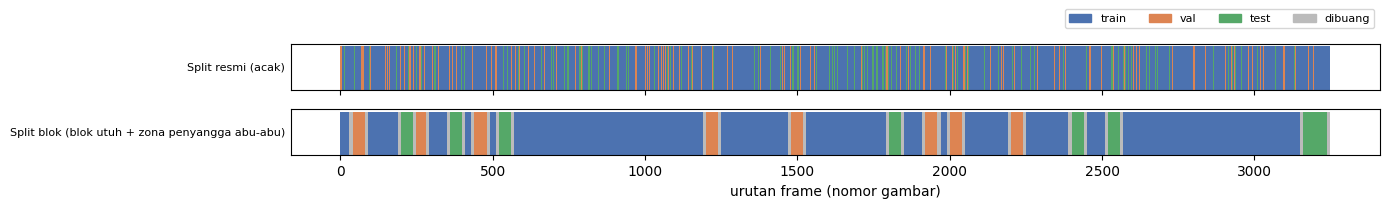

In [5]:
img_tab["blok_id"] = img_tab["rank"] // BLOCK_IMG
nblok = int(img_tab.blok_id.max()) + 1
bx = boxes.merge(img_tab[["image", "blok_id"]], on="image", how="left")
cnt = np.zeros((nblok, 5))
for (b, c), n in bx.groupby(["blok_id", "cls_id"]).size().items():
    cnt[int(b), int(c)] = n
nim = np.bincount(img_tab.blok_id.values, minlength=nblok).astype(float)
tot_c = np.maximum(cnt.sum(0), 1.0)
kv = max(1, int(round(0.10 * nblok))); kt = kv
assert kv + kt < nblok, "Terlalu sedikit blok: kecilkan BLOCK_IMG"

rng_s = np.random.default_rng(SPLIT_SEED); best_alloc = None
for _ in range(N_TRIAL_SPLIT):
    p = rng_s.permutation(nblok); v, t = p[:kv], p[kv:kv + kt]
    cost = ((np.abs(cnt[v].sum(0) / tot_c - 0.10).sum() + np.abs(cnt[t].sum(0) / tot_c - 0.10).sum()) / 0.10
            + (abs(nim[v].sum() / nim.sum() - 0.10) + abs(nim[t].sum() / nim.sum() - 0.10)) / 0.10)
    if best_alloc is None or cost < best_alloc[0]:
        best_alloc = (cost, v.copy(), t.copy())
cost_alloc, v_blk, t_blk = best_alloc
lab_blok = np.zeros(nblok, int); lab_blok[v_blk] = 1; lab_blok[t_blk] = 2       # 0 = train, 1 = val, 2 = test
lab = lab_blok[img_tab.blok_id.values]
keep = np.ones(len(lab), bool)
for i in range(len(lab)):
    w = lab[max(0, i - BUFFER_IMG): i + BUFFER_IMG + 1]
    if lab[i] == 0 and (w > 0).any(): keep[i] = False      # train dibuang jika dekat val/test
    if lab[i] == 1 and (w == 2).any(): keep[i] = False     # val dibuang jika dekat test
img_tab["split_blok"] = np.where(keep, np.array(["train", "val", "test"])[lab], "dibuang")
boxes = boxes.merge(img_tab[["image", "rank", "blok_id", "split_blok"]], on="image", how="left")
assert boxes["split_blok"].notna().all() and len(boxes) == sum(EXPECTED.values())

# ---- pemeriksaan: tidak ada kebocoran lintas split pada protokol blok ----
rk = {s: img_tab.loc[img_tab.split_blok == s, "rank"].values for s in ("train", "val", "test")}
for a_, b_ in [("train", "val"), ("train", "test"), ("val", "test")]:
    gap = np.abs(rk[a_][:, None] - rk[b_][None, :]).min()
    print(f"jarak minimum antar frame {a_}-{b_}: {gap} frame (harus > {BUFFER_IMG})")
    assert gap > BUFFER_IMG, "Zona penyangga dilanggar"

def tab_protokol(col):
    t = boxes.groupby([col, "golongan"]).size().unstack(fill_value=0)
    t["total box"] = t.sum(axis=1); t["gambar"] = boxes.groupby(col)["image"].nunique()
    return t
print(f"\nBlok: {nblok} (@{BLOCK_IMG} frame) | biaya alokasi terbaik: {cost_alloc:.2f}")
print("\nSPLIT BLOK (protokol utama):"); print(tab_protokol("split_blok").to_string())
print("\nSPLIT RESMI (pembanding)    :"); print(tab_protokol("split").to_string())
n_drop = int((img_tab.split_blok == "dibuang").sum())
print(f"\nGambar dibuang (zona penyangga): {n_drop} dari {len(img_tab)} ({n_drop / len(img_tab) * 100:.1f}%)")
cmin = boxes[boxes.split_blok.isin(["val", "test"])].groupby(["split_blok", "golongan"]).size().unstack(fill_value=0)
assert cmin.shape[1] == 5 or DEBUG, "Ada golongan yang hilang dari val/test pada split blok"
assert DEBUG or cmin.values.min() >= 20, f"Golongan langka terlalu sedikit di val/test split blok:\n{cmin}"

fig, ax = plt.subplots(2, 1, figsize=(14, 2.6), sharex=True)
cmap = {"train": "#4c72b0", "val": "#dd8452", "test": "#55a868", "dibuang": "#bbbbbb"}
for a, col, ttl in [(ax[0], "split", "Split resmi (acak)"), (ax[1], "split_blok", "Split blok (blok utuh + zona penyangga abu-abu)")]:
    a.bar(img_tab["rank"], 1, width=1.0, color=[cmap[s] for s in img_tab[col]]); a.set_yticks([]); a.set_ylabel(ttl, rotation=0, ha="right", va="center", fontsize=8)
ax[1].set_xlabel("urutan frame (nomor gambar)")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.values()], labels=list(cmap), ncol=4, fontsize=8, loc="upper right", bbox_to_anchor=(1, 1.9))
plt.tight_layout(); plt.savefig(OUT / "split_blok_timeline.png", dpi=110); plt.show()
img_tab[["image", "img_no", "split", "blok_id", "split_blok"]].to_csv(OUT / "split_blok.csv", index=False)

## 4. Crop per kendaraan
Setiap box dipotong dari gambar asal (koordinat YOLO → piksel, dikunci di tepi gambar) dan disimpan sebagai PNG. Hasilnya **manifest**: satu baris per kendaraan, dengan ukuran crop dalam piksel dan penanda split untuk kedua protokol.

**Cara membaca checkpoint:** jumlah crop = jumlah box (34.408); ukuran crop harus masuk akal (median ±30×36 px). Ukuran crop kecil adalah *batas atas akurasi yang bukan salah model*: golongan truk ditentukan jumlah gandar, dan pada crop yang hanya beberapa piksel gandar tidak terlihat.

In [6]:
CROPS = WORK / "crops"

def crop_box(img, xc, yc, w, h, pad=PAD_FRAC):
    """YOLO ternormalisasi -> crop piksel. Mengembalikan (crop, (x1,y1,x2,y2))."""
    W, H = img.size
    bw, bh = w * W, h * H
    x1 = int(np.floor(xc * W - bw / 2 - pad * bw)); y1 = int(np.floor(yc * H - bh / 2 - pad * bh))
    x2 = int(np.ceil (xc * W + bw / 2 + pad * bw)); y2 = int(np.ceil (yc * H + bh / 2 + pad * bh))
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(W, x2), min(H, y2)
    if x2 <= x1:
        x1 = min(max(0, x1), W - 1); x2 = x1 + 1
    if y2 <= y1:
        y1 = min(max(0, y1), H - 1); y2 = y1 + 1
    return img.crop((x1, y1, x2, y2)), (x1, y1, x2, y2)

recs = []
grp = boxes.groupby(["split", "image"], sort=False)
for (sp, im), g in tqdm(grp, total=grp.ngroups):
    img = Image.open(ROOT / sp / "images" / f"{im}.jpg").convert("RGB")
    W, H = img.size
    for r in g.itertuples():
        c, (x1, y1, x2, y2) = crop_box(img, r.xc, r.yc, r.w, r.h)
        rel = f"{sp}/g{r.golongan}/{im}_{r.box_idx}.png"
        p = CROPS / rel
        p.parent.mkdir(parents=True, exist_ok=True)
        c.save(p)
        recs.append(dict(crop_id=f"{sp}_{im}_{r.box_idx}", split=sp, split_blok=r.split_blok, img_no=r.img_no, blok_id=r.blok_id, frame_rank=r.rank,
                         image=im, box_idx=r.box_idx, cls_id=r.cls_id, golongan=r.golongan, W=W, H=H,
                         x1=x1, y1=y1, x2=x2, y2=y2, pw=x2 - x1, ph=y2 - y1, path=rel))
manifest = pd.DataFrame(recs)
manifest["short"] = manifest[["pw", "ph"]].min(axis=1)

print(manifest.head().to_string())                                  # CHECKPOINT
n_png = sum(1 for _ in CROPS.rglob("*.png"))
print("\nJumlah crop:", len(manifest), "| file PNG:", n_png)
assert len(manifest) == len(boxes) == n_png, "Jumlah crop tidak konsisten"
assert (manifest.pw >= 1).all() and (manifest.ph >= 1).all()
assert (manifest.x2 <= manifest.W).all() and (manifest.y2 <= manifest.H).all()
print("\nUkuran crop (piksel):"); print(manifest[["pw", "ph"]].describe().round(1).to_string())
print("\nResolusi gambar sumber (kamera berbeda):"); print(manifest.groupby(["W", "H"]).size().to_string())

  0%|          | 0/3250 [00:00<?, ?it/s]

          crop_id  split split_blok  img_no  blok_id  frame_rank   image  box_idx  cls_id  golongan    W    H   x1   y1   x2   y2  pw  ph                   path  short
0  train_000002_0  train      train       2        0           1  000002        0       0         1  704  480  445  174  461  192  16  18  train/g1/000002_0.png     16
1  train_000002_1  train      train       2        0           1  000002        1       0         1  704  480  321  190  339  208  18  18  train/g1/000002_1.png     18
2  train_000002_2  train      train       2        0           1  000002        2       1         2  704  480  283  168  306  192  23  24  train/g2/000002_2.png     23
3  train_000002_3  train      train       2        0           1  000002        3       0         1  704  480  398  168  412  183  14  15  train/g1/000002_3.png     14
4  train_000002_4  train      train       2        0           1  000002        4       0         1  704  480  355  172  371  191  16  19  train/g1/000002_4.png

### Keputusan: crop yang terlalu kecil
Tabel menunjukkan **persen crop** di bawah ambang ukuran tertentu per golongan. Default `MIN_SIDE = 0` (tidak ada yang dibuang), yaitu dataset apa adanya. Jika Anda mengubahnya, ubah di sel konfigurasi (Bagian 1), jalankan ulang dari Bagian 3, dan catat alasannya di laporan.

**Cara membaca:** jika mayoritas golongan 1 di bawah 32 px, itu normal (mobil kecil di CCTV jauh). Yang perlu diwaspadai adalah golongan **truk** dengan persentase kecil yang tinggi: model hampir pasti salah di sana, apa pun arsitekturnya.

In [7]:
thr = [8, 12, 16, 24, 32]
tab = pd.DataFrame({f"<{t}px (%)": manifest.groupby("golongan")["short"].apply(lambda s, t=t: (s < t).mean() * 100)
                    for t in thr}).round(1)
print("Persen crop dengan sisi pendek di bawah ambang, per golongan:"); print(tab.to_string())
print("\nMedian sisi pendek per golongan (px):"); print(manifest.groupby("golongan")["short"].median().to_string())

m = manifest[manifest.short >= MIN_SIDE].copy()
dropped = manifest[manifest.short < MIN_SIDE]
print(f"\nMIN_SIDE={MIN_SIDE}: dibuang {len(dropped)} dari {len(manifest)} crop")
for sc in PROTOKOL:
    tr_n = m[m[COL[sc]] == "train"].groupby("golongan").size()
    print(f"[{sc}] crop train per golongan:", tr_n.to_dict())
    assert DEBUG or tr_n.min() >= 100, f"Protokol {sc}: ada golongan dengan <100 crop di train; pertimbangkan ulang MIN_SIDE"
# jumlah crop train per golongan (untuk bobot kelas), dihitung SEBELUM mode DEBUG memotong data
COUNTS_TRAIN = {sc: np.bincount(m[m[COL[sc]] == "train"].cls_id.values, minlength=5) for sc in PROTOKOL}
if DEBUG:
    m = m.groupby(["split", "split_blok", "golongan"]).head(DEBUG_PER_CLASS).reset_index(drop=True)
    print("DEBUG: data dikecilkan menjadi", len(m), "crop")

Persen crop dengan sisi pendek di bawah ambang, per golongan:
          <8px (%)  <12px (%)  <16px (%)  <24px (%)  <32px (%)
golongan                                                      
1              0.0        2.2       21.8       51.4       65.8
2              0.0        0.0        1.6       23.4       42.6
3              0.0        0.0        0.1        5.3       19.0
4              0.0        0.0        0.0        3.9       18.2
5              0.0        0.0        0.0        4.9       18.7

Median sisi pendek per golongan (px):
golongan
1    23.0
2    36.0
3    48.0
4    56.5
5    63.0

MIN_SIDE=0: dibuang 0 dari 34408 crop
[blok] crop train per golongan: {1: 14579, 2: 7365, 3: 1878, 4: 299, 5: 476}
[resmi] crop train per golongan: {1: 16384, 2: 7683, 3: 2154, 4: 316, 5: 526}


### Visualisasi A — distribusi kelas dan ukuran crop
Tiga grafik yang menjadi dasar argumen di laporan: ketimpangan kelas (split resmi), ukuran crop per golongan, dan ragam kamera.

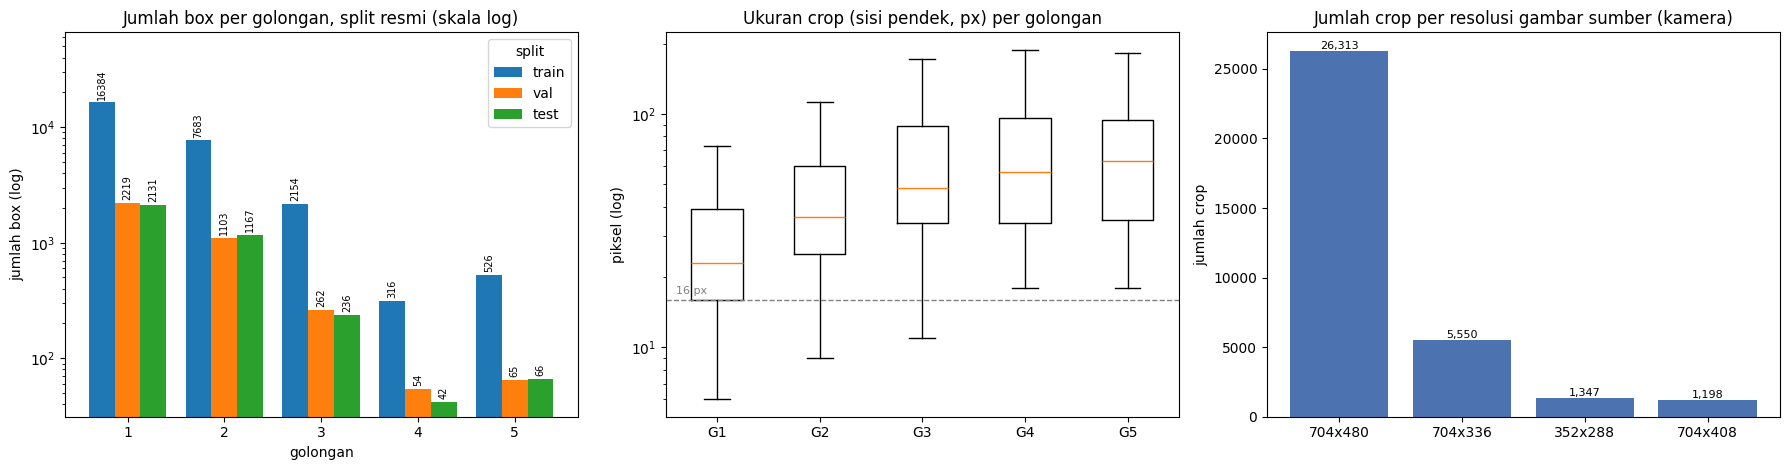

Cara membaca: kiri = ketimpangan kelas (G4 dan G5 jauh lebih sedikit); tengah = golongan truk punya crop lebih besar tetapi tetap banyak yang kecil; kanan = ada beberapa kamera dengan resolusi berbeda.


In [8]:
ct_split = pd.crosstab(boxes.golongan, boxes.split)[["train", "val", "test"]]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

ct_split.plot(kind="bar", ax=axes[0], logy=True, rot=0, width=0.8)
axes[0].set_title("Jumlah box per golongan, split resmi (skala log)"); axes[0].set_xlabel("golongan"); axes[0].set_ylabel("jumlah box (log)")
for c in axes[0].containers:
    axes[0].bar_label(c, fontsize=7, rotation=90, padding=2)
axes[0].set_ylim(top=axes[0].get_ylim()[1] * 3)

data = [manifest.loc[manifest.golongan == g, "short"].values for g in range(1, 6)]
axes[1].boxplot(data, showfliers=False)
axes[1].set_xticklabels([f"G{g}" for g in range(1, 6)])
axes[1].set_yscale("log"); axes[1].axhline(16, ls="--", c="gray", lw=1)
axes[1].text(0.6, 17, "16 px", color="gray", fontsize=8)
axes[1].set_title("Ukuran crop (sisi pendek, px) per golongan"); axes[1].set_ylabel("piksel (log)")

res_ct = manifest.groupby(["W", "H"]).size().sort_values(ascending=False)
axes[2].bar([f"{w}x{h}" for w, h in res_ct.index], res_ct.values, color="#4c72b0")
axes[2].set_title("Jumlah crop per resolusi gambar sumber (kamera)"); axes[2].set_ylabel("jumlah crop")
for i, v in enumerate(res_ct.values):
    axes[2].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "eda_distribusi_ukuran.png", dpi=110); plt.show()
print("Cara membaca: kiri = ketimpangan kelas (G4 dan G5 jauh lebih sedikit); tengah = golongan truk punya crop lebih besar "
      "tetapi tetap banyak yang kecil; kanan = ada beberapa kamera dengan resolusi berbeda.")

## 5. Pemeriksaan visual
**Wajib dilihat sebelum training.** Jawab dan catat:
1. **Apakah kelasnya masuk akal?** Baris 1 (golongan 1) harus mobil/bus/pick-up; baris 2–5 truk dengan gandar bertambah. Jika terbalik, pemetaan `cls_id + 1` salah dan semua hasil tidak valid.
2. **Apakah kendaraan terpotong** (terutama roda di bawah)? Jika sering, naikkan `PAD_FRAC` (mis. 0,1) di Bagian 1 dan ulangi dari Bagian 3.
3. **Apakah plat nomor terbaca?** Jika ya, sensor sebelum gambar dipublikasikan di website.

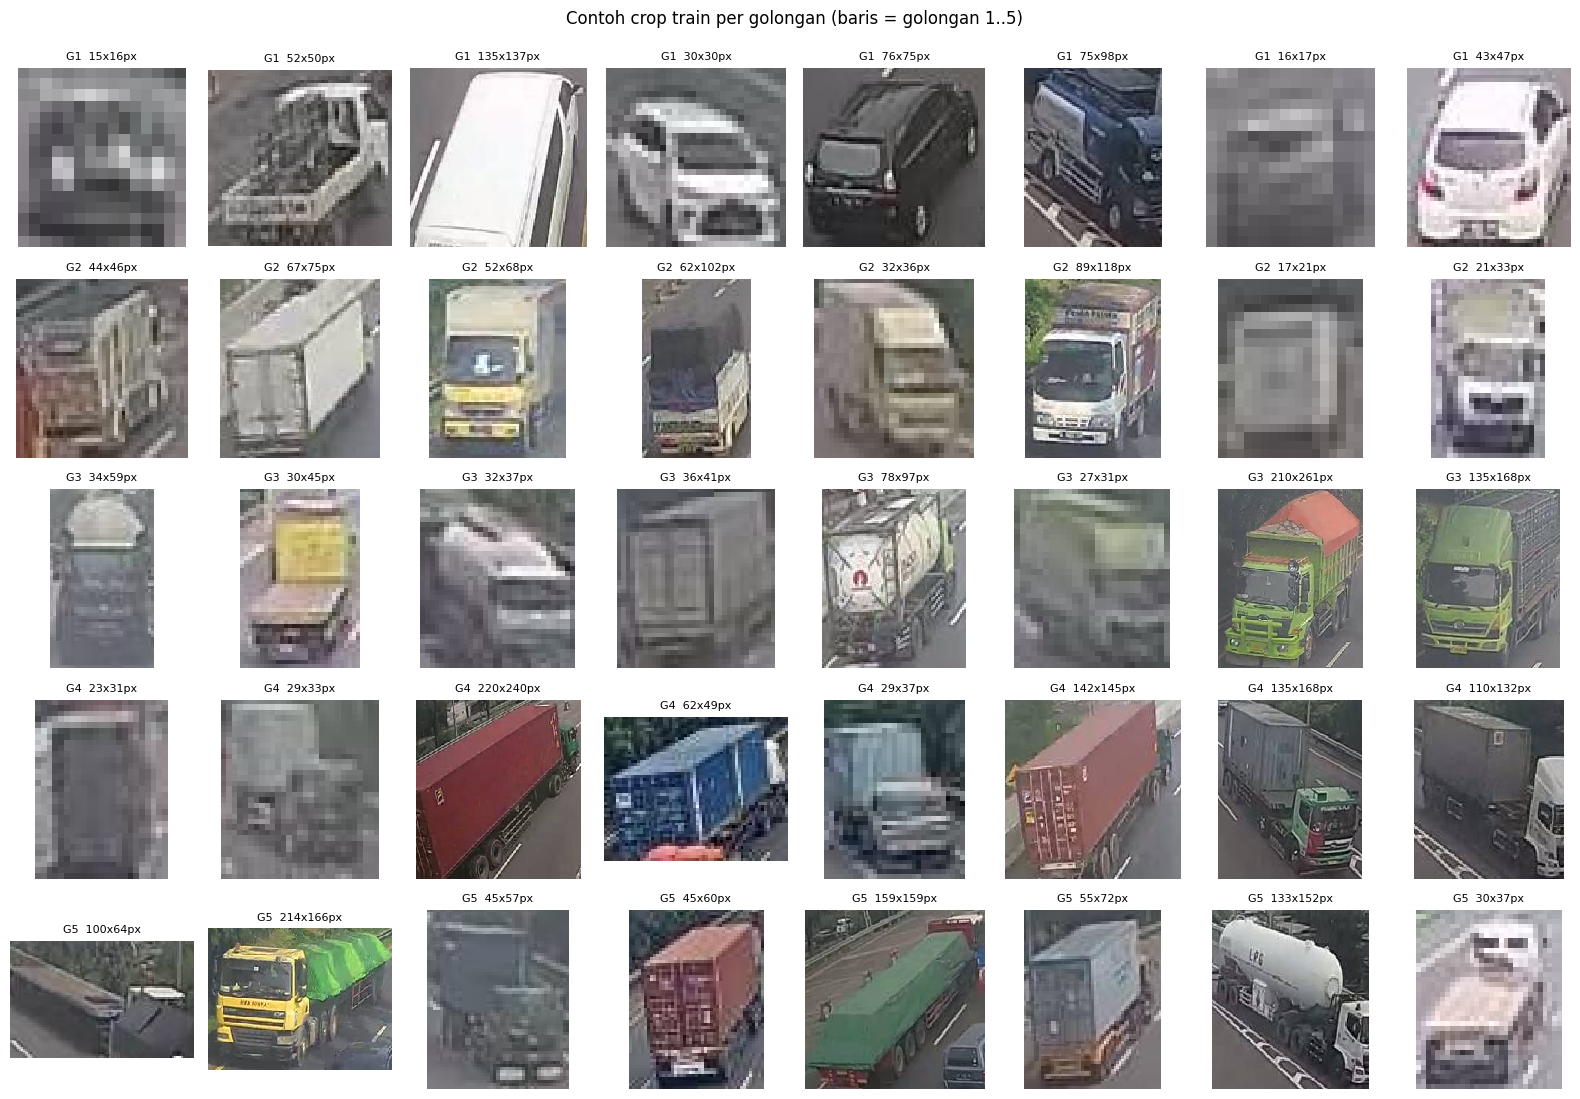

In [9]:
fig, axes = plt.subplots(5, 8, figsize=(16, 11))
for gi in range(1, 6):
    sub = m[(m.split == "train") & (m.golongan == gi)]
    pick = sub.sample(min(8, len(sub)), random_state=SEED)
    for j in range(8):
        ax = axes[gi - 1, j]; ax.axis("off")
        if j < len(pick):
            r = pick.iloc[j]
            ax.imshow(Image.open(CROPS / r.path), interpolation="nearest")
            ax.set_title(f"G{gi}  {r.pw}x{r.ph}px", fontsize=8)
plt.suptitle("Contoh crop train per golongan (baris = golongan 1..5)", y=0.995)
plt.tight_layout(); plt.savefig(OUT / "qa_grid.png", dpi=110); plt.show()

## 6. Baseline "hanya ukuran box"
Truk lebih besar dari mobil, jadi **ukuran crop saja sudah memprediksi golongan sampai batas tertentu**. Baseline ini tidak melihat piksel gambar, hanya lebar, tinggi, dan rasio. Fungsinya sebagai **lantai**: jika model deep learning hanya sedikit di atasnya, model belum tentu mengenali gandar.

Di bagian ini hanya **train → val** yang dipakai, untuk tiap protokol. Evaluasi test untuk baseline dilakukan bersama model di Bagian 12.

**Cara membaca:** bandingkan *macro-F1* (bukan akurasi). "Selalu tebak golongan 1" mendapat akurasi ±60% tetapi macro-F1 sangat rendah. Itu contoh kenapa akurasi menyesatkan pada data timpang.

In [10]:
def feats(d):
    return np.c_[d.pw, d.ph, d.pw / d.ph]

BASE_VAL = {}
for sc in PROTOKOL:
    tr_b, va_b = m[m[COL[sc]] == "train"], m[m[COL[sc]] == "val"]
    res = {}
    maj = tr_b.cls_id.mode()[0]
    pred = np.full(len(va_b), maj)
    res["selalu tebak kelas terbanyak"] = (accuracy_score(va_b.cls_id, pred), f1_score(va_b.cls_id, pred, average="macro", labels=range(5), zero_division=0))
    for name, cw in [("RandomForest ukuran box", None), ("RandomForest ukuran box (balanced)", "balanced")]:
        rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight=cw, random_state=SEED, n_jobs=-1)
        rf.fit(feats(tr_b), tr_b.cls_id)
        pred = rf.predict(feats(va_b))
        res[name] = (accuracy_score(va_b.cls_id, pred), f1_score(va_b.cls_id, pred, average="macro", labels=range(5), zero_division=0))
    BASE_VAL[sc] = pd.DataFrame(res, index=["akurasi (val)", "macro-F1 (val)"]).T.round(3)
    print(f"\nBaseline, protokol '{sc}':"); print(BASE_VAL[sc].to_string())


Baseline, protokol 'blok':
                                    akurasi (val)  macro-F1 (val)
selalu tebak kelas terbanyak                0.627           0.154
RandomForest ukuran box                     0.659           0.279
RandomForest ukuran box (balanced)          0.539           0.292

Baseline, protokol 'resmi':
                                    akurasi (val)  macro-F1 (val)
selalu tebak kelas terbanyak                0.599           0.150
RandomForest ukuran box                     0.653           0.307
RandomForest ukuran box (balanced)          0.555           0.311


## 7. Menyiapkan data untuk training
Semua crop dimuat **sekali** ke memori GPU sebagai gambar 128×128 (aspek tidak dipertahankan, di-*stretch*; kebanyakan crop aslinya jauh lebih kecil dari 128 px sehingga tidak ada detail yang hilang). Tiap protokol hanya menyimpan **indeks** train/val/test ke tensor yang sama, jadi tidak ada duplikasi memori. Di GPU, tiap batch di-*resize* ke resolusi masing-masing model (224 px untuk ConvNeXt dan DeiT III; 256 px untuk Swin V2) dan dinormalisasi.

**Augmentasi (hanya train):** flip horizontal acak, perubahan kecerahan dan kontras ±20%. Val dan test tanpa augmentasi.

**Bobot kelas** untuk Fase 2 dihitung dari jumlah crop train tiap protokol: `bobot = N / (jumlah_kelas × n_kelas)`.

In [11]:
R_STORE = 128
def load_arr(df):
    arr = np.empty((len(df), R_STORE, R_STORE, 3), np.uint8)
    for i, p in enumerate(tqdm(df.path.values)):
        arr[i] = np.asarray(Image.open(CROPS / p).convert("RGB").resize((R_STORE, R_STORE), Image.BICUBIC))
    return arr

m = m.reset_index(drop=True)                      # indeks baris m = indeks baris X_all
X_all = torch.from_numpy(load_arr(m)).to(dev)
y_all = m.cls_id.values.astype(np.int64)
y_all_t = torch.as_tensor(y_all, device=dev)

D = {}
for sc in PROTOKOL:
    ix = {s: np.where(m[COL[sc]].values == s)[0] for s in SPLITS}
    assert not (set(ix["train"]) & set(ix["val"])) and not (set(ix["train"]) & set(ix["test"])) and not (set(ix["val"]) & set(ix["test"])), "Indeks split tumpang tindih"
    cnt_tr = COUNTS_TRAIN[sc]
    D[sc] = dict(ix=ix, ix_t={s: torch.as_tensor(v, device=dev) for s, v in ix.items()},
                 y={s: y_all[v] for s, v in ix.items()}, df={s: m.iloc[v].reset_index(drop=True) for s, v in ix.items()},
                 counts=cnt_tr, class_w=torch.tensor(cnt_tr.sum() / (5 * np.maximum(cnt_tr, 1)), dtype=torch.float32, device=dev))
    print(f"[{sc}] crop train/val/test: {len(ix['train'])} / {len(ix['val'])} / {len(ix['test'])}")
print("\ntensor semua crop:", tuple(X_all.shape))
print(pd.DataFrame({f"jumlah_train[{sc}]": D[sc]["counts"] for sc in PROTOKOL} |
                   {f"bobot[{sc}]": D[sc]["class_w"].cpu().numpy().round(2) for sc in PROTOKOL},
                   index=[f"G{i}" for i in range(1, 6)]).to_string())

def prep(xb_uint8, size, mean, std, train):
    x = xb_uint8.permute(0, 3, 1, 2).float().div_(255)
    if train:
        B = x.shape[0]
        flip = torch.rand(B, device=x.device) < 0.5
        x = torch.where(flip[:, None, None, None], x.flip(3), x)
        b = (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.4
        c = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.4
        mu = x.mean(dim=(1, 2, 3), keepdim=True)
        x = ((x - mu) * c + mu + b).clamp_(0, 1)
    x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    return (x - mean) / std

def make_model(name, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    return timm.create_model(name, pretrained=not DEBUG, num_classes=5)   # kepala baru diinisialisasi acak

  0%|          | 0/34408 [00:00<?, ?it/s]

[blok] crop train/val/test: 24597 / 3504 / 3316
[resmi] crop train/val/test: 27063 / 3703 / 3642

tensor semua crop: (34408, 128, 128, 3)
    jumlah_train[blok]  jumlah_train[resmi]  bobot[blok]  bobot[resmi]
G1               14579                16384     0.340000      0.330000
G2                7365                 7683     0.670000      0.700000
G3                1878                 2154     2.620000      2.510000
G4                 299                  316    16.450001     17.129999
G5                 476                  526    10.330000     10.290000


## 8. Uji kecepatan dan estimasi waktu
Sebelum training sungguhan, sel ini membuat tiap model (**mengunduh bobot pra-latih**), menjalankan beberapa langkah training, dan mengestimasi waktu. Jika unduhan bobot gagal, notebook berhenti di sini dengan pesan error (bukan diam-diam memakai bobot acak).

**Cara membaca:** `est_menit_fase1` adalah perkiraan kasar untuk 1 protokol (3 model × seed × epoch, belum termasuk evaluasi per epoch). Jika totalnya terlalu besar, jalankan hanya protokol utama (`PROTOKOL = ["blok"]`) atau kurangi `SEEDS` **sebelum** training dimulai.

In [12]:
def model_cfg(model):
    pc = model.pretrained_cfg
    size = int(pc["input_size"][-1])
    mean = torch.tensor(pc["mean"], device=dev).view(1, 3, 1, 1)
    std = torch.tensor(pc["std"], device=dev).view(1, 3, 1, 1)
    return size, mean, std

bench = []
ix_b = D[UTAMA]["ix_t"]["train"]; n_b = len(ix_b)
for key, cfg in MODELS.items():
    model = make_model(cfg["name"], 0).to(dev)
    size, mean, std = model_cfg(model)
    params = sum(p.numel() for p in model.parameters()) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    bs = min(BATCH, n_b); model.train(); times = []
    for it in range(8):
        gi = ix_b[torch.randint(0, n_b, (bs,), device=dev)]
        if use_amp: torch.cuda.synchronize()
        t0 = time.time()
        xb = prep(X_all[gi], size, mean, std, True)
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
            loss = F.cross_entropy(model(xb).float(), y_all_t[gi])
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        if use_amp: torch.cuda.synchronize()
        if it >= 3: times.append(time.time() - t0)
    s_it = float(np.mean(times)); steps_ep = math.ceil(n_b / BATCH)
    bench.append(dict(model=key, timm_name=cfg["name"], params_M=round(params, 1), input_px=size,
                      detik_per_iter=round(s_it, 3), est_menit_per_epoch=round(s_it * steps_ep / 60, 2),
                      est_menit_fase1=round(s_it * steps_ep * EPOCHS * len(SEEDS) / 60, 1)))
    del model, opt; torch.cuda.empty_cache() if use_amp else None
bench = pd.DataFrame(bench)
print(bench.to_string(index=False))
tot1 = bench.est_menit_fase1.sum()
print(f"\nEstimasi Fase 1 per protokol: {tot1:.0f} menit (+ evaluasi per epoch, kira-kira +15-25%).")
print(f"Fase 2 (1 model terbaik x {len(SEEDS)} seed): {bench.est_menit_fase1.min():.0f}-{bench.est_menit_fase1.max():.0f} menit.")
print(f"Total perkiraan untuk {len(PROTOKOL)} protokol: {(tot1 * len(PROTOKOL) + bench.est_menit_fase1.mean()) * 1.2 / 60:.1f} jam.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.3MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

     model                       timm_name  params_M  input_px  detik_per_iter  est_menit_per_epoch  est_menit_fase1
ConvNeXt-T           convnext_tiny.fb_in1k      27.8       224           0.258                 1.66             39.8
   DeiT3-S deit3_small_patch16_224.fb_in1k      21.7       224           0.180                 1.15             27.7
  SwinV2-T swinv2_tiny_window8_256.ms_in1k      27.6       256           0.609                 3.91             93.8

Estimasi Fase 1 per protokol: 161 menit (+ evaluasi per epoch, kira-kira +15-25%).
Fase 2 (1 model terbaik x 3 seed): 28-94 menit.
Total perkiraan untuk 2 protokol: 7.5 jam.


## 9. Fungsi training
**Protokol training (sama untuk semua model dan kedua protokol evaluasi):**
- Fine-tune seluruh jaringan, kepala klasifikasi 5 kelas baru. AdamW, learning rate 1e-4 dengan *warmup* 1 epoch lalu *cosine decay*, weight decay 0,05, batch 64, 8 epoch, *gradient clipping* 1,0, mixed precision.
- **Epoch terbaik dipilih berdasarkan macro-F1 di val.** Test tidak dipakai untuk memilih apa pun.
- Setelah training, bobot epoch terbaik dimuat dan **test dievaluasi satu kali per run**. Prediksi val dan test disimpan agar analisis bisa diulang tanpa melatih lagi.
- Hasil tiap run disimpan sebagai JSON (+ prediksi `.npz`) di `runs/` dengan nama `<protokol>_<model>_<loss>_s<seed>`; run yang sudah ada dilewati. Konfigurasi disimpan di JSON; konfigurasi yang berbeda ditolak.

**Catatan jujur:** training GPU tidak sepenuhnya deterministik walau seed sama, jadi angka bisa sedikit berbeda jika diulang. Itulah alasan tiap model dilatih 3 seed dan dilaporkan sebagai rata-rata ± simpangan baku.

In [13]:
@torch.no_grad()
def predict(model, ix_t, size, mean, std):
    model.eval(); out = []
    for i in range(0, len(ix_t), 256):
        xb = prep(X_all[ix_t[i:i + 256]], size, mean, std, False)
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(xb).float().argmax(1).cpu())
    return torch.cat(out).numpy()

def macro_f1(y, p):
    return f1_score(y, p, average="macro", labels=range(5), zero_division=0)

def results_df(sc=None):
    rows = [json.loads(f.read_text()) for f in sorted(RES.glob("[!_]*.json"))]
    R = pd.DataFrame(rows)
    if sc is not None and len(R):
        R = R[R["scheme"] == sc].reset_index(drop=True)
    return R

def run_one(sc, mkey, loss_type, seed, verbose=True):
    tag = f"{sc}_{mkey}_{loss_type}_s{seed}"
    fj = RES / f"{tag}.json"
    CFG_NOW = dict(epochs=EPOCHS, lr=LR, wd=WD, batch=BATCH, min_side=MIN_SIDE, pad=PAD_FRAC, debug=DEBUG,
                   block=BLOCK_IMG if sc == "blok" else None, buffer=BUFFER_IMG if sc == "blok" else None,
                   split_seed=SPLIT_SEED if sc == "blok" else None)
    if fj.exists():
        d_old = json.loads(fj.read_text())
        if d_old.get("cfg") != CFG_NOW:
            raise RuntimeError(f"Run {tag} dibuat dengan konfigurasi berbeda: {d_old.get('cfg')} != sekarang {CFG_NOW}. "
                               f"Kembalikan konfigurasi, atau mulai bersih dengan memindahkan folder hasil.")
        return d_old
    d = D[sc]; ix_tr = d["ix_t"]["train"]; ix_va, ix_te = d["ix_t"]["val"], d["ix_t"]["test"]; yva, yte = d["y"]["val"], d["y"]["test"]
    model = make_model(MODELS[mkey]["name"], seed).to(dev)
    size, mean, std = model_cfg(model)
    params = sum(p.numel() for p in model.parameters()) / 1e6
    n = len(ix_tr); steps_ep = math.ceil(n / BATCH); total = EPOCHS * steps_ep; warm = steps_ep
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    crit = nn.CrossEntropyLoss(weight=d["class_w"] if loss_type == "berbobot" else None)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    g = torch.Generator().manual_seed(seed)
    hist, best_f1, best_ep, best_state = [], -1.0, 0, None
    t_start = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(n, generator=g).to(dev); tl = 0.0; t_ep = time.time()
        for i in range(0, n, BATCH):
            gi = ix_tr[perm[i:i + BATCH]]
            xb = prep(X_all[gi], size, mean, std, True); yb = y_all_t[gi]
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp):
                logits = model(xb)
            loss = crit(logits.float(), yb)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Loss tidak valid (NaN/inf) pada {tag}, epoch {ep}. Turunkan LR (mis. 5e-5) di Bagian 1 (lalu mulai bersih).")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(gi)
        pv = predict(model, ix_va, size, mean, std)
        f1v, acc = macro_f1(yva, pv), accuracy_score(yva, pv)
        hist.append(dict(epoch=ep, train_loss=tl / n, val_f1=f1v, val_acc=acc, sec=time.time() - t_ep))
        if f1v > best_f1:
            best_f1, best_ep = f1v, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  [{tag}] ep {ep}/{EPOCHS} loss {tl / n:.3f} | val macro-F1 {f1v:.3f} acc {acc:.3f} | {time.time() - t_ep:.0f}s")
    model.load_state_dict(best_state)
    pv, pt = predict(model, ix_va, size, mean, std), predict(model, ix_te, size, mean, std)
    out = dict(tag=tag, scheme=sc, model=mkey, loss=loss_type, seed=seed, params_M=round(params, 1), best_epoch=best_ep,
               n_train=n, val_f1=macro_f1(yva, pv), val_acc=accuracy_score(yva, pv),
               test_f1=macro_f1(yte, pt), test_acc=accuracy_score(yte, pt),
               test_f1_cls=list(f1_score(yte, pt, average=None, labels=range(5), zero_division=0)),
               val_f1_cls=list(f1_score(yva, pv, average=None, labels=range(5), zero_division=0)),
               train_sec=time.time() - t_start, history=hist, cfg=CFG_NOW)
    np.savez(RES / f"{tag}.npz", val=pv, test=pt)
    fj.write_text(json.dumps(out))
    del model, opt, best_state
    if use_amp: torch.cuda.empty_cache()
    print(f"==> {tag}: epoch terbaik {best_ep} | val F1 {out['val_f1']:.3f} | TEST F1 {out['test_f1']:.3f} acc {out['test_acc']:.3f} "
          f"| {out['train_sec'] / 60:.1f} menit")
    return out

def fase1(sc):
    for seed in SEEDS:
        for mkey in MODELS:
            run_one(sc, mkey, "biasa", seed)

def pilih_terbaik(sc):
    """Model terbaik = rata-rata macro-F1 VAL tertinggi pada Fase 1 protokol sc (bukan test)."""
    R = results_df(sc)
    r1 = R[R["loss"] == "biasa"].groupby("model")["val_f1"].mean().sort_values(ascending=False)
    print(f"Rata-rata macro-F1 VAL, Fase 1, protokol '{sc}':"); print(r1.round(4).to_string())
    return r1.index[0]

## 10. Fase 1 dan Fase 2
**Urutan dibuat agar hasil terpenting selesai lebih dulu:** (a) Fase 1 protokol utama, (b) Fase 2 (pembobotan kelas) pada protokol utama, (c) Fase 1 protokol pembanding. Jika waktu tidak cukup, Anda boleh berhenti setelah (b) dan memakai Bagian 11 sampai 14 untuk protokol utama saja; sel analisis otomatis melewati protokol yang belum ada hasilnya.

Di dalam Fase 1: seed terluar, model terdalam, jadi jika waktu habis di tengah, ketiga model tetap lengkap untuk seed yang sudah selesai. **Jika Colab terputus, jalankan ulang notebook dari atas (Run all)**; run yang sudah tersimpan dilewati.

### 10a. Fase 1, protokol utama — tiga arsitektur dengan loss biasa

In [14]:
t0 = time.time()
fase1(UTAMA)
print(f"\nFase 1 protokol '{UTAMA}' selesai. Waktu sesi ini: {(time.time() - t0) / 60:.1f} menit")

  [blok_ConvNeXt-T_biasa_s0] ep 1/8 loss 0.634 | val macro-F1 0.429 acc 0.867 | 121s
  [blok_ConvNeXt-T_biasa_s0] ep 2/8 loss 0.253 | val macro-F1 0.601 acc 0.891 | 127s
  [blok_ConvNeXt-T_biasa_s0] ep 3/8 loss 0.153 | val macro-F1 0.681 acc 0.909 | 127s
  [blok_ConvNeXt-T_biasa_s0] ep 4/8 loss 0.083 | val macro-F1 0.727 acc 0.902 | 127s
  [blok_ConvNeXt-T_biasa_s0] ep 5/8 loss 0.037 | val macro-F1 0.759 acc 0.912 | 126s
  [blok_ConvNeXt-T_biasa_s0] ep 6/8 loss 0.016 | val macro-F1 0.753 acc 0.910 | 125s
  [blok_ConvNeXt-T_biasa_s0] ep 7/8 loss 0.008 | val macro-F1 0.751 acc 0.911 | 125s
  [blok_ConvNeXt-T_biasa_s0] ep 8/8 loss 0.005 | val macro-F1 0.763 acc 0.912 | 126s
==> blok_ConvNeXt-T_biasa_s0: epoch terbaik 8 | val F1 0.763 | TEST F1 0.804 acc 0.929 | 16.9 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [blok_DeiT3-S_biasa_s0] ep 1/8 loss 0.447 | val macro-F1 0.540 acc 0.887 | 92s
  [blok_DeiT3-S_biasa_s0] ep 2/8 loss 0.233 | val macro-F1 0.640 acc 0.894 | 91s
  [blok_DeiT3-S_biasa_s0] ep 3/8 loss 0.145 | val macro-F1 0.654 acc 0.903 | 91s
  [blok_DeiT3-S_biasa_s0] ep 4/8 loss 0.075 | val macro-F1 0.703 acc 0.895 | 90s
  [blok_DeiT3-S_biasa_s0] ep 5/8 loss 0.030 | val macro-F1 0.726 acc 0.906 | 89s
  [blok_DeiT3-S_biasa_s0] ep 6/8 loss 0.012 | val macro-F1 0.722 acc 0.906 | 89s
  [blok_DeiT3-S_biasa_s0] ep 7/8 loss 0.004 | val macro-F1 0.725 acc 0.906 | 89s
  [blok_DeiT3-S_biasa_s0] ep 8/8 loss 0.002 | val macro-F1 0.724 acc 0.906 | 89s
==> blok_DeiT3-S_biasa_s0: epoch terbaik 5 | val F1 0.726 | TEST F1 0.810 acc 0.928 | 12.1 menit
  [blok_SwinV2-T_biasa_s0] ep 1/8 loss 0.510 | val macro-F1 0.591 acc 0.872 | 291s
  [blok_SwinV2-T_biasa_s0] ep 2/8 loss 0.270 | val macro-F1 0.550 acc 0.877 | 289s
  [blok_SwinV2-T_biasa_s0] ep 3/8 loss 0.180 | val macro-F1 0.663 acc 0.887 | 288s
  [blo

/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [blok_DeiT3-S_biasa_s1] ep 1/8 loss 0.471 | val macro-F1 0.618 acc 0.894 | 92s
  [blok_DeiT3-S_biasa_s1] ep 2/8 loss 0.236 | val macro-F1 0.647 acc 0.882 | 91s
  [blok_DeiT3-S_biasa_s1] ep 3/8 loss 0.146 | val macro-F1 0.731 acc 0.912 | 91s
  [blok_DeiT3-S_biasa_s1] ep 4/8 loss 0.079 | val macro-F1 0.710 acc 0.901 | 90s
  [blok_DeiT3-S_biasa_s1] ep 5/8 loss 0.034 | val macro-F1 0.707 acc 0.908 | 89s
  [blok_DeiT3-S_biasa_s1] ep 6/8 loss 0.012 | val macro-F1 0.745 acc 0.912 | 89s
  [blok_DeiT3-S_biasa_s1] ep 7/8 loss 0.004 | val macro-F1 0.742 acc 0.911 | 89s
  [blok_DeiT3-S_biasa_s1] ep 8/8 loss 0.003 | val macro-F1 0.732 acc 0.910 | 89s
==> blok_DeiT3-S_biasa_s1: epoch terbaik 6 | val F1 0.745 | TEST F1 0.798 acc 0.921 | 12.1 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [blok_SwinV2-T_biasa_s1] ep 1/8 loss 0.512 | val macro-F1 0.559 acc 0.872 | 292s
  [blok_SwinV2-T_biasa_s1] ep 2/8 loss 0.267 | val macro-F1 0.652 acc 0.894 | 290s
  [blok_SwinV2-T_biasa_s1] ep 3/8 loss 0.185 | val macro-F1 0.672 acc 0.908 | 288s
  [blok_SwinV2-T_biasa_s1] ep 4/8 loss 0.121 | val macro-F1 0.659 acc 0.892 | 288s
  [blok_SwinV2-T_biasa_s1] ep 5/8 loss 0.075 | val macro-F1 0.688 acc 0.904 | 287s
  [blok_SwinV2-T_biasa_s1] ep 6/8 loss 0.039 | val macro-F1 0.694 acc 0.902 | 284s
  [blok_SwinV2-T_biasa_s1] ep 7/8 loss 0.021 | val macro-F1 0.703 acc 0.906 | 281s
  [blok_SwinV2-T_biasa_s1] ep 8/8 loss 0.014 | val macro-F1 0.714 acc 0.909 | 280s
==> blok_SwinV2-T_biasa_s1: epoch terbaik 8 | val F1 0.714 | TEST F1 0.790 acc 0.923 | 38.6 menit
  [blok_ConvNeXt-T_biasa_s2] ep 1/8 loss 0.622 | val macro-F1 0.488 acc 0.876 | 128s
  [blok_ConvNeXt-T_biasa_s2] ep 2/8 loss 0.262 | val macro-F1 0.650 acc 0.900 | 127s
  [blok_ConvNeXt-T_biasa_s2] ep 3/8 loss 0.157 | val macro-F1 0.685 

/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [blok_DeiT3-S_biasa_s2] ep 1/8 loss 0.449 | val macro-F1 0.578 acc 0.872 | 92s
  [blok_DeiT3-S_biasa_s2] ep 2/8 loss 0.230 | val macro-F1 0.660 acc 0.894 | 92s
  [blok_DeiT3-S_biasa_s2] ep 3/8 loss 0.141 | val macro-F1 0.718 acc 0.896 | 91s
  [blok_DeiT3-S_biasa_s2] ep 4/8 loss 0.074 | val macro-F1 0.677 acc 0.901 | 90s
  [blok_DeiT3-S_biasa_s2] ep 5/8 loss 0.032 | val macro-F1 0.698 acc 0.904 | 89s
  [blok_DeiT3-S_biasa_s2] ep 6/8 loss 0.010 | val macro-F1 0.710 acc 0.906 | 89s
  [blok_DeiT3-S_biasa_s2] ep 7/8 loss 0.004 | val macro-F1 0.693 acc 0.904 | 89s
  [blok_DeiT3-S_biasa_s2] ep 8/8 loss 0.002 | val macro-F1 0.693 acc 0.905 | 89s
==> blok_DeiT3-S_biasa_s2: epoch terbaik 3 | val F1 0.718 | TEST F1 0.809 acc 0.919 | 12.1 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [blok_SwinV2-T_biasa_s2] ep 1/8 loss 0.513 | val macro-F1 0.596 acc 0.879 | 292s
  [blok_SwinV2-T_biasa_s2] ep 2/8 loss 0.271 | val macro-F1 0.677 acc 0.890 | 290s
  [blok_SwinV2-T_biasa_s2] ep 3/8 loss 0.183 | val macro-F1 0.700 acc 0.898 | 288s
  [blok_SwinV2-T_biasa_s2] ep 4/8 loss 0.124 | val macro-F1 0.694 acc 0.901 | 288s
  [blok_SwinV2-T_biasa_s2] ep 5/8 loss 0.071 | val macro-F1 0.744 acc 0.907 | 287s
  [blok_SwinV2-T_biasa_s2] ep 6/8 loss 0.038 | val macro-F1 0.723 acc 0.901 | 284s
  [blok_SwinV2-T_biasa_s2] ep 7/8 loss 0.022 | val macro-F1 0.718 acc 0.906 | 280s
  [blok_SwinV2-T_biasa_s2] ep 8/8 loss 0.015 | val macro-F1 0.726 acc 0.907 | 280s
==> blok_SwinV2-T_biasa_s2: epoch terbaik 5 | val F1 0.744 | TEST F1 0.778 acc 0.920 | 38.6 menit

Fase 1 protokol 'blok' selesai. Waktu sesi ini: 203.2 menit


### 10b. Fase 2, protokol utama — pembobotan kelas pada model terbaik
Model terbaik dipilih berdasarkan **rata-rata macro-F1 di val** (bukan test) pada Fase 1. Model itu dilatih ulang dengan loss berbobot (bobot di Bagian 7), seed yang sama. Perbandingan "dengan bobot vs tanpa bobot" hanya berlaku untuk model tersebut.

**Opsional:** set `RUN_AB = True` untuk melatih loss berbobot pada **semua** model (rancangan A+B penuh, +6 run).

In [15]:
RUN_AB = False
BEST_UTAMA = pilih_terbaik(UTAMA)
print("\nModel terbaik (berdasarkan val):", BEST_UTAMA)
t0 = time.time()
for seed in SEEDS:
    for mkey in (list(MODELS) if RUN_AB else [BEST_UTAMA]):
        run_one(UTAMA, mkey, "berbobot", seed)
print(f"\nFase 2 selesai. Waktu sesi ini: {(time.time() - t0) / 60:.1f} menit")

Rata-rata macro-F1 VAL, Fase 1, protokol 'blok':
model
ConvNeXt-T    0.7435
SwinV2-T      0.7336
DeiT3-S       0.7297

Model terbaik (berdasarkan val): ConvNeXt-T
  [blok_ConvNeXt-T_berbobot_s0] ep 1/8 loss 1.168 | val macro-F1 0.618 acc 0.848 | 128s
  [blok_ConvNeXt-T_berbobot_s0] ep 2/8 loss 0.600 | val macro-F1 0.712 acc 0.893 | 127s
  [blok_ConvNeXt-T_berbobot_s0] ep 3/8 loss 0.329 | val macro-F1 0.687 acc 0.902 | 127s
  [blok_ConvNeXt-T_berbobot_s0] ep 4/8 loss 0.155 | val macro-F1 0.725 acc 0.899 | 127s
  [blok_ConvNeXt-T_berbobot_s0] ep 5/8 loss 0.074 | val macro-F1 0.739 acc 0.906 | 126s
  [blok_ConvNeXt-T_berbobot_s0] ep 6/8 loss 0.030 | val macro-F1 0.718 acc 0.903 | 125s
  [blok_ConvNeXt-T_berbobot_s0] ep 7/8 loss 0.020 | val macro-F1 0.716 acc 0.903 | 125s
  [blok_ConvNeXt-T_berbobot_s0] ep 8/8 loss 0.013 | val macro-F1 0.723 acc 0.906 | 125s
==> blok_ConvNeXt-T_berbobot_s0: epoch terbaik 5 | val F1 0.739 | TEST F1 0.793 acc 0.919 | 17.0 menit
  [blok_ConvNeXt-T_berbobot_s1

### 10c. Fase 1, protokol pembanding (split resmi)
Hanya Fase 1 (loss biasa). Tujuannya mengukur **seberapa besar kebocoran temporal menaikkan skor**, dan menghubungkan hasil dengan split resmi dataset. Jika `PROTOKOL` hanya berisi satu protokol, sel ini tidak melakukan apa-apa.

In [16]:
t0 = time.time()
for sc in PROTOKOL[1:]:
    fase1(sc)
print(f"\nFase 1 protokol pembanding selesai (atau tidak ada). Waktu sesi ini: {(time.time() - t0) / 60:.1f} menit")

  [resmi_ConvNeXt-T_biasa_s0] ep 1/8 loss 0.611 | val macro-F1 0.551 acc 0.879 | 141s
  [resmi_ConvNeXt-T_biasa_s0] ep 2/8 loss 0.229 | val macro-F1 0.726 acc 0.911 | 140s
  [resmi_ConvNeXt-T_biasa_s0] ep 3/8 loss 0.134 | val macro-F1 0.765 acc 0.907 | 139s
  [resmi_ConvNeXt-T_biasa_s0] ep 4/8 loss 0.070 | val macro-F1 0.791 acc 0.910 | 139s
  [resmi_ConvNeXt-T_biasa_s0] ep 5/8 loss 0.031 | val macro-F1 0.802 acc 0.921 | 139s
  [resmi_ConvNeXt-T_biasa_s0] ep 6/8 loss 0.013 | val macro-F1 0.815 acc 0.924 | 138s
  [resmi_ConvNeXt-T_biasa_s0] ep 7/8 loss 0.006 | val macro-F1 0.824 acc 0.924 | 138s
  [resmi_ConvNeXt-T_biasa_s0] ep 8/8 loss 0.004 | val macro-F1 0.818 acc 0.923 | 138s
==> resmi_ConvNeXt-T_biasa_s0: epoch terbaik 7 | val F1 0.824 | TEST F1 0.774 acc 0.928 | 18.8 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [resmi_DeiT3-S_biasa_s0] ep 1/8 loss 0.432 | val macro-F1 0.665 acc 0.884 | 101s
  [resmi_DeiT3-S_biasa_s0] ep 2/8 loss 0.220 | val macro-F1 0.708 acc 0.910 | 101s
  [resmi_DeiT3-S_biasa_s0] ep 3/8 loss 0.133 | val macro-F1 0.763 acc 0.913 | 99s
  [resmi_DeiT3-S_biasa_s0] ep 4/8 loss 0.073 | val macro-F1 0.764 acc 0.906 | 99s
  [resmi_DeiT3-S_biasa_s0] ep 5/8 loss 0.031 | val macro-F1 0.794 acc 0.923 | 99s
  [resmi_DeiT3-S_biasa_s0] ep 6/8 loss 0.011 | val macro-F1 0.809 acc 0.925 | 98s
  [resmi_DeiT3-S_biasa_s0] ep 7/8 loss 0.005 | val macro-F1 0.808 acc 0.923 | 98s
  [resmi_DeiT3-S_biasa_s0] ep 8/8 loss 0.003 | val macro-F1 0.806 acc 0.925 | 97s
==> resmi_DeiT3-S_biasa_s0: epoch terbaik 6 | val F1 0.809 | TEST F1 0.794 acc 0.935 | 13.3 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [resmi_SwinV2-T_biasa_s0] ep 1/8 loss 0.492 | val macro-F1 0.660 acc 0.886 | 319s
  [resmi_SwinV2-T_biasa_s0] ep 2/8 loss 0.249 | val macro-F1 0.745 acc 0.915 | 318s
  [resmi_SwinV2-T_biasa_s0] ep 3/8 loss 0.171 | val macro-F1 0.739 acc 0.911 | 315s
  [resmi_SwinV2-T_biasa_s0] ep 4/8 loss 0.114 | val macro-F1 0.779 acc 0.915 | 315s
  [resmi_SwinV2-T_biasa_s0] ep 5/8 loss 0.065 | val macro-F1 0.811 acc 0.922 | 313s
  [resmi_SwinV2-T_biasa_s0] ep 6/8 loss 0.036 | val macro-F1 0.827 acc 0.929 | 310s
  [resmi_SwinV2-T_biasa_s0] ep 7/8 loss 0.020 | val macro-F1 0.817 acc 0.927 | 308s
  [resmi_SwinV2-T_biasa_s0] ep 8/8 loss 0.014 | val macro-F1 0.830 acc 0.930 | 307s
==> resmi_SwinV2-T_biasa_s0: epoch terbaik 8 | val F1 0.830 | TEST F1 0.781 acc 0.934 | 42.3 menit
  [resmi_ConvNeXt-T_biasa_s1] ep 1/8 loss 0.606 | val macro-F1 0.535 acc 0.866 | 139s
  [resmi_ConvNeXt-T_biasa_s1] ep 2/8 loss 0.238 | val macro-F1 0.697 acc 0.897 | 139s
  [resmi_ConvNeXt-T_biasa_s1] ep 3/8 loss 0.143 | val mac

/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [resmi_DeiT3-S_biasa_s1] ep 1/8 loss 0.455 | val macro-F1 0.682 acc 0.874 | 101s
  [resmi_DeiT3-S_biasa_s1] ep 2/8 loss 0.224 | val macro-F1 0.773 acc 0.911 | 101s
  [resmi_DeiT3-S_biasa_s1] ep 3/8 loss 0.138 | val macro-F1 0.778 acc 0.902 | 100s
  [resmi_DeiT3-S_biasa_s1] ep 4/8 loss 0.075 | val macro-F1 0.807 acc 0.916 | 99s
  [resmi_DeiT3-S_biasa_s1] ep 5/8 loss 0.034 | val macro-F1 0.792 acc 0.920 | 99s
  [resmi_DeiT3-S_biasa_s1] ep 6/8 loss 0.011 | val macro-F1 0.795 acc 0.923 | 99s
  [resmi_DeiT3-S_biasa_s1] ep 7/8 loss 0.005 | val macro-F1 0.813 acc 0.924 | 98s
  [resmi_DeiT3-S_biasa_s1] ep 8/8 loss 0.003 | val macro-F1 0.817 acc 0.926 | 98s
==> resmi_DeiT3-S_biasa_s1: epoch terbaik 8 | val F1 0.817 | TEST F1 0.797 acc 0.935 | 13.4 menit
  [resmi_SwinV2-T_biasa_s1] ep 1/8 loss 0.490 | val macro-F1 0.698 acc 0.892 | 321s
  [resmi_SwinV2-T_biasa_s1] ep 2/8 loss 0.257 | val macro-F1 0.753 acc 0.907 | 320s
  [resmi_SwinV2-T_biasa_s1] ep 3/8 loss 0.173 | val macro-F1 0.696 acc 0.89

/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [resmi_DeiT3-S_biasa_s2] ep 1/8 loss 0.440 | val macro-F1 0.611 acc 0.889 | 101s
  [resmi_DeiT3-S_biasa_s2] ep 2/8 loss 0.217 | val macro-F1 0.723 acc 0.901 | 100s
  [resmi_DeiT3-S_biasa_s2] ep 3/8 loss 0.131 | val macro-F1 0.744 acc 0.906 | 100s
  [resmi_DeiT3-S_biasa_s2] ep 4/8 loss 0.070 | val macro-F1 0.791 acc 0.922 | 99s
  [resmi_DeiT3-S_biasa_s2] ep 5/8 loss 0.032 | val macro-F1 0.782 acc 0.923 | 98s
  [resmi_DeiT3-S_biasa_s2] ep 6/8 loss 0.011 | val macro-F1 0.768 acc 0.918 | 98s
  [resmi_DeiT3-S_biasa_s2] ep 7/8 loss 0.004 | val macro-F1 0.805 acc 0.923 | 98s
  [resmi_DeiT3-S_biasa_s2] ep 8/8 loss 0.002 | val macro-F1 0.796 acc 0.923 | 97s
==> resmi_DeiT3-S_biasa_s2: epoch terbaik 7 | val F1 0.805 | TEST F1 0.811 acc 0.934 | 13.3 menit


/tmp/ipykernel_402/3679031622.py:58: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [resmi_SwinV2-T_biasa_s2] ep 1/8 loss 0.497 | val macro-F1 0.601 acc 0.878 | 319s
  [resmi_SwinV2-T_biasa_s2] ep 2/8 loss 0.258 | val macro-F1 0.741 acc 0.903 | 320s
  [resmi_SwinV2-T_biasa_s2] ep 3/8 loss 0.176 | val macro-F1 0.775 acc 0.911 | 318s
  [resmi_SwinV2-T_biasa_s2] ep 4/8 loss 0.116 | val macro-F1 0.789 acc 0.922 | 316s
  [resmi_SwinV2-T_biasa_s2] ep 5/8 loss 0.069 | val macro-F1 0.816 acc 0.925 | 313s
  [resmi_SwinV2-T_biasa_s2] ep 6/8 loss 0.038 | val macro-F1 0.809 acc 0.920 | 311s
  [resmi_SwinV2-T_biasa_s2] ep 7/8 loss 0.018 | val macro-F1 0.821 acc 0.921 | 308s
  [resmi_SwinV2-T_biasa_s2] ep 8/8 loss 0.013 | val macro-F1 0.823 acc 0.921 | 306s
==> resmi_SwinV2-T_biasa_s2: epoch terbaik 8 | val F1 0.823 | TEST F1 0.778 acc 0.928 | 42.3 menit

Fase 1 protokol pembanding selesai (atau tidak ada). Waktu sesi ini: 223.2 menit


## 11. Tabel hasil
Sel pertama mengumpulkan semua hasil tiap protokol (prediksi test dari tiap run, baseline ukuran box, dan interval kepercayaan). Sel berikutnya menampilkan tabel. Rata-rata ± simpangan baku dari semua seed. **Macro-F1 di test adalah angka utama.**

**Cara membaca:**
- Simpangan baku antar seed mengukur seberapa stabil hasil training. Jika selisih dua model **lebih kecil dari simpangan baku**, jangan menyebut satu "lebih baik".
- `best_epoch` yang sama dengan `EPOCHS` berarti model masih membaik saat training berhenti (kemungkinan belum konvergen pada anggaran epoch ini); yang sangat awal berarti *overfitting*.
- Bandingkan dengan baseline ukuran box (Bagian 6). Model yang hampir sama dengan baseline belum membuktikan ia mengenali gandar.
- Protokol **blok** adalah angka utama; protokol **resmi** adalah pembanding yang berpotensi mengandung kebocoran temporal (Bagian 3); apakah pengaruhnya terlihat pada skor dijawab di Bagian 12h.

In [17]:
K = 5; KLS = [f"G{i}" for i in range(1, 6)]
def f1_vec(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)
def recall_vec(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K); tp = np.diag(cm).astype(float); sup = cm.sum(1)
    return np.divide(tp, sup, out=np.zeros(K), where=sup > 0)
def ci(a): return np.percentile(a, [2.5, 97.5])
def ms(x):
    x = np.asarray(x, float)
    return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}" if len(x) > 1 else f"{x.mean():.3f} (n=1)"

def kumpulkan(sc):
    """Mengumpulkan semua hasil satu protokol ke dict A (prediksi, baseline, bootstrap, tabel CI)."""
    R = results_df(sc)
    n_run = R[R["loss"] == "biasa"].groupby("model").size()
    if len(n_run) != len(MODELS) or (n_run != len(SEEDS)).any():
        print(f"PERINGATAN: Fase 1 protokol '{sc}' belum lengkap (run per model: {n_run.to_dict()}).")
    d = D[sc]; te, tr_df_, yte = d["df"]["test"], d["df"]["train"], d["y"]["test"]
    r1 = R[R["loss"] == "biasa"].groupby("model")["val_f1"].mean().sort_values(ascending=False)
    A = dict(sc=sc, R=R, te=te, yte=yte, best=r1.index[0], val_rank=r1, out=OUT / sc)
    A["out"].mkdir(exist_ok=True)
    tags = {}
    for _, r in R.iterrows():
        tags.setdefault((r["model"], r["loss"]), []).append(r["tag"])
    P = {k: np.vstack([np.load(RES / f"{t}.npz")["test"] for t in sorted(v)]) for k, v in tags.items()}      # (n_seed, N_test)
    for nm, cw in [("Baseline-RF", None), ("Baseline-RF-balanced", "balanced")]:      # baseline ukuran box: dilatih di train protokol ini
        ps = []
        for s in SEEDS:
            rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight=cw, random_state=s, n_jobs=-1)
            rf.fit(feats(tr_df_), tr_df_.cls_id); ps.append(rf.predict(feats(te)))
        P[(nm, "-")] = np.vstack(ps)
    k0 = next(iter(P)); assert abs(f1_vec(yte, P[k0][0]).mean() - macro_f1(yte, P[k0][0])) < 1e-9      # titik cek vs sklearn
    A["P"] = P

    # cluster bootstrap: kelompok BOOT_FRAMES frame berurutan = satu klaster (frame bertetangga saling berkorelasi)
    codes, _ = pd.factorize(te["frame_rank"] // BOOT_FRAMES)
    groups = [np.where(codes == g)[0] for g in range(codes.max() + 1)]
    rng = np.random.default_rng(SEED)
    boot_idx = [np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))]) for _ in range(BOOT_B)]
    BOOT = {}
    for k, v in P.items():
        out = np.empty((BOOT_B, K))
        for b, idx in enumerate(boot_idx):
            out[b] = np.mean([f1_vec(yte[idx], pr[idx]) for pr in v], axis=0)
        BOOT[k] = out
    A["BOOT"] = BOOT; A["n_klaster"] = len(groups)

    rows = []
    for k, v in P.items():
        pt = np.mean([f1_vec(yte, pr) for pr in v], axis=0); lo, hi = ci(BOOT[k].mean(1))
        rows.append({"model": k[0], "loss": k[1], "macro-F1 test": round(pt.mean(), 3), "CI95 bawah": round(lo, 3), "CI95 atas": round(hi, 3),
                     **{f"F1 G{i+1}": round(pt[i], 3) for i in range(K)}})
    A["ci_tab"] = pd.DataFrame(rows).sort_values("macro-F1 test", ascending=False).reset_index(drop=True)
    names = [k for k in P if k[1] == "biasa"]
    diff_rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            dd = BOOT[names[i]].mean(1) - BOOT[names[j]].mean(1); lo, hi = ci(dd)
            diff_rows.append({"A": names[i][0], "B": names[j][0], "selisih A-B": round(dd.mean(), 3), "CI bawah": round(lo, 3), "CI atas": round(hi, 3),
                              "dapat dibedakan?": "ya" if (lo > 0 or hi < 0) else "tidak (CI mencakup 0)"})
    A["diff_tab"] = pd.DataFrame(diff_rows)
    return A

ANALISIS = {}
for sc in PROTOKOL:
    if len(results_df(sc)):
        ANALISIS[sc] = kumpulkan(sc)
        print(f"Protokol '{sc}': {len(ANALISIS[sc]['R'])} run dimuat | model terbaik menurut VAL: {ANALISIS[sc]['best']} | klaster bootstrap: {ANALISIS[sc]['n_klaster']}")
    else:
        print(f"Protokol '{sc}': belum ada hasil, dilewati.")
assert UTAMA in ANALISIS, "Belum ada hasil protokol utama: jalankan Bagian 10a."

def judul(A):
    print("\n" + "=" * 90); print(f"PROTOKOL: {A['sc']}" + ("  (UTAMA)" if A["sc"] == UTAMA else "  (pembanding)")); print("=" * 90)

Protokol 'blok': 12 run dimuat | model terbaik menurut VAL: ConvNeXt-T | klaster bootstrap: 32
Protokol 'resmi': 9 run dimuat | model terbaik menurut VAL: SwinV2-T | klaster bootstrap: 204



PROTOKOL: blok  (UTAMA)
     model     loss  n_seed  params_M  val macro-F1 TEST macro-F1  TEST akurasi best_epoch  menit/run
ConvNeXt-T berbobot       3      27.8 0.741 ± 0.007 0.770 ± 0.025 0.912 ± 0.009    2, 5, 5       17.0
ConvNeXt-T    biasa       3      27.8 0.744 ± 0.017 0.801 ± 0.017 0.927 ± 0.006    6, 8, 8       17.0
   DeiT3-S    biasa       3      21.7 0.730 ± 0.014 0.806 ± 0.007 0.923 ± 0.005    3, 5, 6       12.1
  SwinV2-T    biasa       3      27.6 0.734 ± 0.017 0.783 ± 0.007 0.922 ± 0.002    5, 6, 8       38.6
  Catatan: ConvNeXt-T: epoch terbaik = epoch terakhir pada 2/3 run (kemungkinan belum konvergen penuh pada anggaran 8 epoch).
  Catatan: SwinV2-T: epoch terbaik = epoch terakhir pada 1/3 run (kemungkinan belum konvergen penuh pada anggaran 8 epoch).

F1 per golongan di TEST (rata-rata seed):
                        G1     G2     G3     G4     G5
ConvNeXt-T|berbobot  0.977  0.856  0.684  0.579  0.756
ConvNeXt-T|biasa     0.979  0.884  0.716  0.606  0.818
DeiT3-S

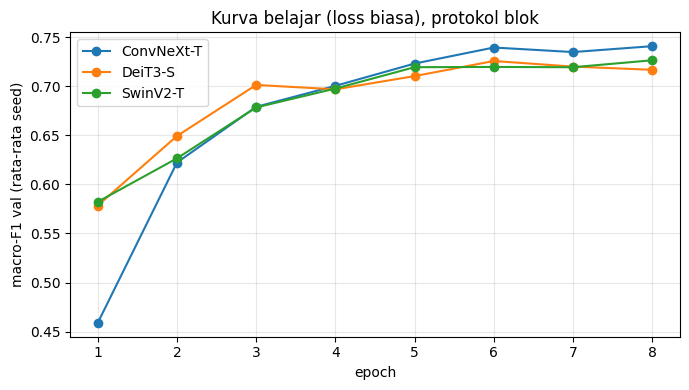


PROTOKOL: resmi  (pembanding)
     model  loss  n_seed  params_M  val macro-F1 TEST macro-F1  TEST akurasi best_epoch  menit/run
ConvNeXt-T biasa       3      27.8 0.813 ± 0.010 0.776 ± 0.005 0.930 ± 0.004    5, 7, 8       18.7
   DeiT3-S biasa       3      21.7 0.810 ± 0.006 0.801 ± 0.009 0.935 ± 0.001    6, 7, 8       13.3
  SwinV2-T biasa       3      27.6 0.820 ± 0.013 0.782 ± 0.004 0.931 ± 0.003    8, 8, 8       42.3
  Catatan: ConvNeXt-T: epoch terbaik = epoch terakhir pada 1/3 run (kemungkinan belum konvergen penuh pada anggaran 8 epoch).
  Catatan: DeiT3-S: epoch terbaik = epoch terakhir pada 1/3 run (kemungkinan belum konvergen penuh pada anggaran 8 epoch).
  Catatan: SwinV2-T: epoch terbaik = epoch terakhir pada 3/3 run (kemungkinan belum konvergen penuh pada anggaran 8 epoch).

F1 per golongan di TEST (rata-rata seed):
                     G1     G2     G3     G4     G5
ConvNeXt-T|biasa  0.977  0.906  0.725  0.510  0.760
DeiT3-S|biasa     0.979  0.912  0.749  0.618  0.746
S

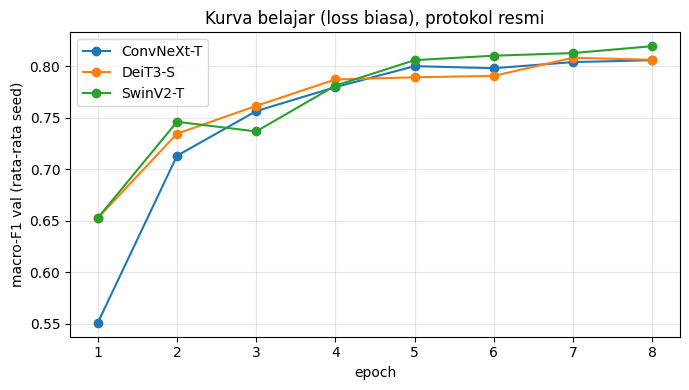

In [18]:
def tampil_hasil(A):
    R = A["R"]; rows = []
    for (mk, ls), d in R.groupby(["model", "loss"]):
        rows.append({"model": mk, "loss": ls, "n_seed": len(d), "params_M": d.params_M.iloc[0],
                     "val macro-F1": ms(d.val_f1), "TEST macro-F1": ms(d.test_f1), "TEST akurasi": ms(d.test_acc),
                     "best_epoch": ", ".join(map(str, sorted(d.best_epoch))), "menit/run": round(d.train_sec.mean() / 60, 1)})
    A["summary"] = pd.DataFrame(rows)
    print(A["summary"].to_string(index=False))
    for mk, d in R[R["loss"] == "biasa"].groupby("model"):
        n_last = int((d.best_epoch == EPOCHS).sum())
        if n_last:
            print(f"  Catatan: {mk}: epoch terbaik = epoch terakhir pada {n_last}/{len(d)} run (kemungkinan belum konvergen penuh pada anggaran {EPOCHS} epoch).")
    pc = {f"{mk}|{ls}": np.mean(np.vstack(d.test_f1_cls.values), axis=0) for (mk, ls), d in R.groupby(["model", "loss"])}
    A["pc_tab"] = pd.DataFrame(pc, index=KLS).T.round(3)
    print("\nF1 per golongan di TEST (rata-rata seed):"); print(A["pc_tab"].to_string())
    fig, ax = plt.subplots(figsize=(7, 4))
    for mk, d in R[R["loss"] == "biasa"].groupby("model"):
        H = np.vstack([[h["val_f1"] for h in hh] for hh in d.history.values])
        ax.plot(range(1, H.shape[1] + 1), H.mean(0), marker="o", label=mk)
    ax.set_xlabel("epoch"); ax.set_ylabel("macro-F1 val (rata-rata seed)"); ax.set_title(f"Kurva belajar (loss biasa), protokol {A['sc']}")
    ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(A["out"] / "kurva_belajar.png", dpi=110); plt.show()

for A in ANALISIS.values():
    judul(A); tampil_hasil(A)

## 12. Analisis
**Interval kepercayaan** memakai *cluster bootstrap* (1.000 resampel) dengan klaster = `BOOT_FRAMES` frame berurutan, bukan per gambar atau per crop, karena crop dalam satu gambar dan frame bertetangga saling berkorelasi. Ini mengukur ketidakpastian akibat ukuran test set (golongan 4 hanya puluhan crop). Ia **tidak** mengukur variasi training; itu ditunjukkan simpangan baku antar seed.

**Cara membaca:**
- *Selisih berpasangan:* jika interval 95% selisih **mencakup 0**, dua model tidak dapat dibedakan pada test set ini.
- *Confusion matrix* (baris = golongan sebenarnya, dinormalisasi per baris): diagonal = *recall* per golongan. Sel di luar diagonal yang besar menunjukkan golongan yang tertukar.
- *Laporan per golongan:* presisi, recall, F1 tiap golongan. Presisi rendah dengan recall tinggi berarti model terlalu sering menebak golongan itu.

### 12a. Interval kepercayaan dan selisih berpasangan

In [19]:
def tampil_ci(A):
    print("Macro-F1 TEST dengan interval kepercayaan 95% (cluster bootstrap):"); print(A["ci_tab"].to_string(index=False))
    print("\nCI95 F1 untuk golongan langka (G4, G5):")
    for k in A["P"]:
        if k[0].startswith("Baseline"): continue
        c4, c5 = ci(A["BOOT"][k][:, 3]), ci(A["BOOT"][k][:, 4])
        print(f"  {k[0]:11s} {k[1]:8s}  G4 [{c4[0]:.2f}, {c4[1]:.2f}]   G5 [{c5[0]:.2f}, {c5[1]:.2f}]")
    print("\nSelisih macro-F1 berpasangan (model biasa), CI95:"); print(A["diff_tab"].to_string(index=False))
    print(f"\nJumlah crop test per golongan: " + ", ".join(f"G{c+1}={int((A['yte'] == c).sum())}" for c in range(K)))

for A in ANALISIS.values():
    judul(A); tampil_ci(A)


PROTOKOL: blok  (UTAMA)
Macro-F1 TEST dengan interval kepercayaan 95% (cluster bootstrap):
               model     loss  macro-F1 test  CI95 bawah  CI95 atas  F1 G1  F1 G2  F1 G3  F1 G4  F1 G5
             DeiT3-S    biasa          0.806       0.747      0.847  0.980  0.871  0.709  0.655  0.814
          ConvNeXt-T    biasa          0.801       0.741      0.842  0.979  0.884  0.716  0.606  0.818
            SwinV2-T    biasa          0.783       0.722      0.830  0.980  0.875  0.696  0.594  0.767
          ConvNeXt-T berbobot          0.770       0.716      0.807  0.977  0.856  0.684  0.579  0.756
Baseline-RF-balanced        -          0.299       0.278      0.320  0.716  0.398  0.232  0.005  0.142
         Baseline-RF        -          0.291       0.270      0.314  0.785  0.421  0.187  0.000  0.063

CI95 F1 untuk golongan langka (G4, G5):
  ConvNeXt-T  berbobot  G4 [0.39, 0.72]   G5 [0.58, 0.84]
  ConvNeXt-T  biasa     G4 [0.37, 0.76]   G5 [0.69, 0.89]
  DeiT3-S     biasa     G4 [0.

### 12b. Confusion matrix
Model terbaik **menurut val** (bukan test), loss biasa, dijumlahkan seluruh seed. Jika model itu punya varian berbobot (Fase 2), keduanya ditampilkan berdampingan.


PROTOKOL: blok  (UTAMA)


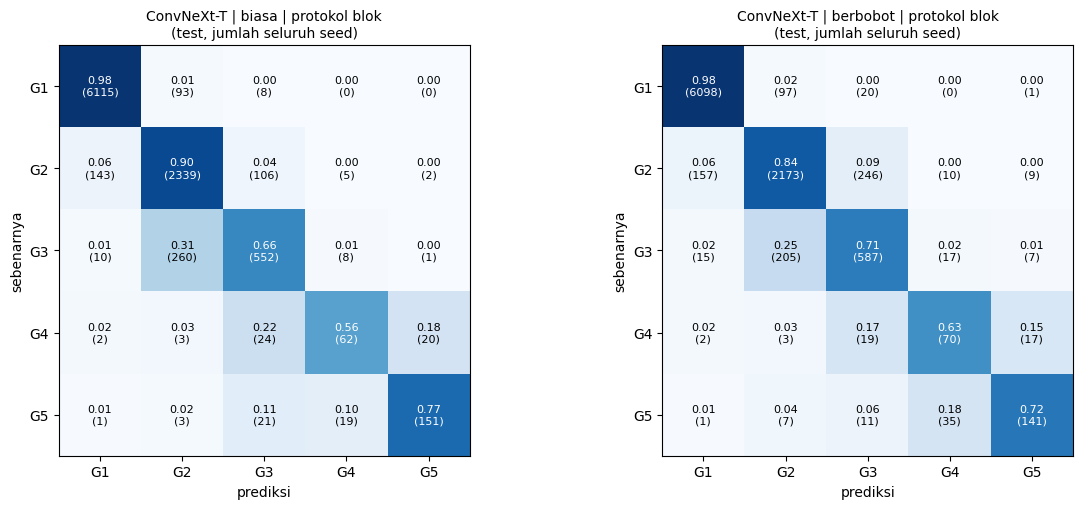


PROTOKOL: resmi  (pembanding)


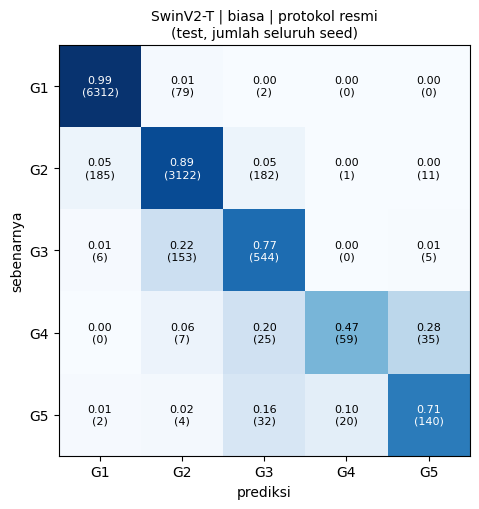

In [20]:
def conf(A, key):
    cm = np.zeros((K, K))
    for pr in A["P"][key]: cm += np.bincount(A["yte"] * K + pr, minlength=K * K).reshape(K, K)
    return cm

def tampil_cm(A):
    variants = [(A["best"], "biasa")] + ([(A["best"], "berbobot")] if (A["best"], "berbobot") in A["P"] else [])
    fig, axes = plt.subplots(1, len(variants), figsize=(6.2 * len(variants), 5.2)); axes = np.atleast_1d(axes)
    for ax, key in zip(axes, variants):
        cm = conf(A, key); cmn = cm / cm.sum(1, keepdims=True).clip(1)
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{cmn[i, j]:.2f}\n({int(cm[i, j])})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
        ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(KLS); ax.set_yticklabels(KLS)
        ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya"); ax.set_title(f"{key[0]} | {key[1]} | protokol {A['sc']}\n(test, jumlah seluruh seed)", fontsize=10)
    plt.tight_layout(); plt.savefig(A["out"] / "confusion_matrix.png", dpi=110); plt.show()

for A in ANALISIS.values():
    judul(A); tampil_cm(A)

### 12c. Laporan per golongan (presisi, recall, F1)
Rata-rata seed, untuk tiap model dengan loss biasa (dan varian berbobot jika ada). `support` = jumlah crop test golongan itu.

In [21]:
def tampil_cr(A):
    rows = []
    for key in [k for k in A["P"] if k[1] != "-"] + [("Baseline-RF", "-")]:
        pr_, rc_, f_ = [], [], []
        for p in A["P"][key]:
            a, b, c, _ = precision_recall_fscore_support(A["yte"], p, labels=range(K), zero_division=0)
            pr_.append(a); rc_.append(b); f_.append(c)
        pr_, rc_, f_ = np.mean(pr_, 0), np.mean(rc_, 0), np.mean(f_, 0)
        for c in range(K):
            rows.append(dict(model=key[0], loss=key[1], golongan=KLS[c], presisi=round(pr_[c], 3), recall=round(rc_[c], 3), F1=round(f_[c], 3), support=int((A["yte"] == c).sum())))
    A["cr_tab"] = pd.DataFrame(rows)
    for (mk, ls), d in A["cr_tab"].groupby(["model", "loss"], sort=False):
        if mk.startswith("Baseline-RF-bal"): continue
        print(f"\n{mk} | {ls}"); print(d.drop(columns=["model", "loss"]).to_string(index=False))

for A in ANALISIS.values():
    judul(A); tampil_cr(A)


PROTOKOL: blok  (UTAMA)

ConvNeXt-T | berbobot
golongan  presisi  recall    F1  support
      G1    0.972   0.981 0.977     2072
      G2    0.876   0.837 0.856      865
      G3    0.664   0.706 0.684      277
      G4    0.556   0.631 0.579       37
      G5    0.840   0.723 0.756       65

ConvNeXt-T | biasa
golongan  presisi  recall    F1  support
      G1    0.975   0.984 0.979     2072
      G2    0.867   0.901 0.884      865
      G3    0.776   0.664 0.716      277
      G4    0.667   0.559 0.606       37
      G5    0.869   0.774 0.818       65

DeiT3-S | biasa
golongan  presisi  recall    F1  support
      G1    0.975   0.985 0.980     2072
      G2    0.872   0.871 0.871      865
      G3    0.735   0.694 0.709      277
      G4    0.712   0.613 0.655       37
      G5    0.849   0.785 0.814       65

SwinV2-T | biasa
golongan  presisi  recall    F1  support
      G1    0.976   0.985 0.980     2072
      G2    0.866   0.885 0.875      865
      G3    0.736   0.662 0.696     

### 12d. Pengaruh ukuran crop (recall per golongan per rentang ukuran)
**Akurasi total per rentang ukuran tidak dipakai**, karena crop kecil hampir seluruhnya G1 (kelas termudah) sehingga akurasinya tercampur komposisi kelas. Yang dipakai adalah **recall per golongan** pada tiap rentang ukuran (sisi pendek crop), dengan tabel jumlah crop per sel supaya terlihat mana yang cukup sampel.

**Cara membaca:** bandingkan baris golongan yang **sama** antar rentang (terutama G2 dan G3). Sel dengan n < 10 tidak dilaporkan. Untuk G4 dan G5 jumlah crop per rentang kecil, jadi jangan membuat klaim tren.


PROTOKOL: blok  (UTAMA)
Jumlah crop TEST per golongan x rentang ukuran (komposisi kelas tiap rentang):
short     <16 px  16-31 px  32-63 px  >=64 px
golongan                                     
1            544       874       459      195
2             16       400       240      209
3              0        54        90      133
4              0         4         6       27
5              0         3        10       52
Persen G1 di tiap rentang: {'<16 px': 97.1, '16-31 px': 65.5, '32-63 px': 57.0, '>=64 px': 31.7}

Recall per golongan per ukuran crop, ConvNeXt-T (loss biasa, rata-rata seed; NaN = n<10):
    <16 px  16-31 px  32-63 px  >=64 px
G1   0.992     0.979     0.981    0.986
G2   0.625     0.898     0.915    0.914
G3     NaN     0.370     0.641    0.799
G4     NaN       NaN       NaN    0.642
G5     NaN       NaN     0.667    0.840

Recall per golongan per ukuran crop, DeiT3-S (loss biasa, rata-rata seed; NaN = n<10):
    <16 px  16-31 px  32-63 px  >=64 px
G1   0.996     0.9

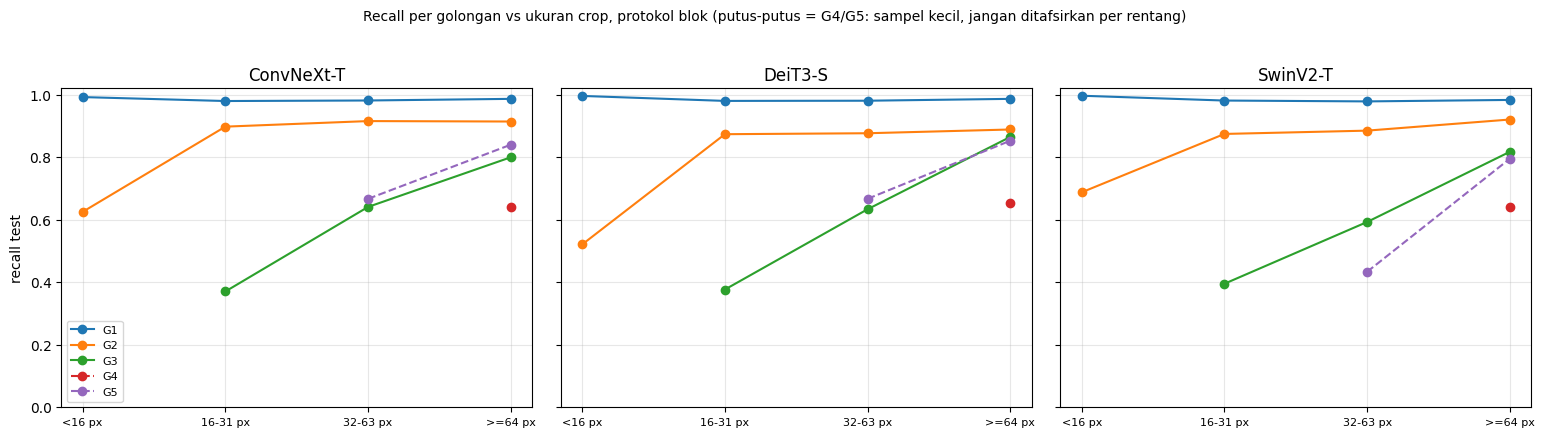


PROTOKOL: resmi  (pembanding)
Jumlah crop TEST per golongan x rentang ukuran (komposisi kelas tiap rentang):
short     <16 px  16-31 px  32-63 px  >=64 px
golongan                                     
1            544       884       506      197
2             39       506       349      273
3              1        39       113       83
4              0        11        11       20
5              0        13        20       33
Persen G1 di tiap rentang: {'<16 px': 93.2, '16-31 px': 60.8, '32-63 px': 50.7, '>=64 px': 32.5}

Recall per golongan per ukuran crop, ConvNeXt-T (loss biasa, rata-rata seed; NaN = n<10):
    <16 px  16-31 px  32-63 px  >=64 px
G1   0.997     0.976     0.984    0.995
G2   0.530     0.891     0.907    0.954
G3     NaN     0.376     0.782    0.847
G4     NaN     0.303     0.485    0.417
G5     NaN     0.641     0.650    0.838

Recall per golongan per ukuran crop, DeiT3-S (loss biasa, rata-rata seed; NaN = n<10):
    <16 px  16-31 px  32-63 px  >=64 px
G1   0.999  

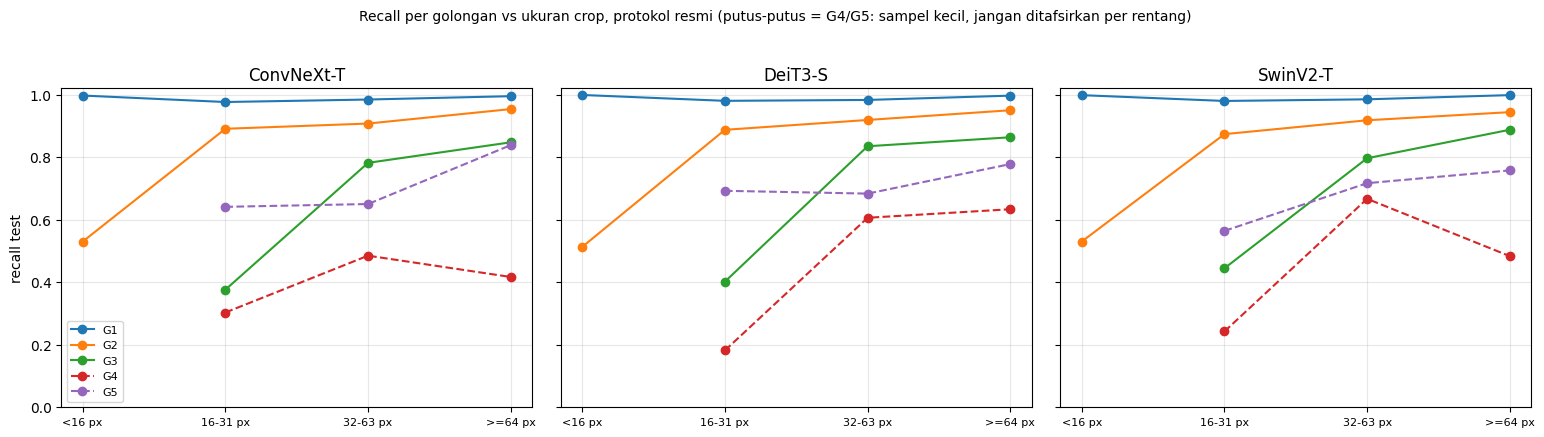

In [22]:
edges = [0, 16, 32, 64, 1e9]; labs = ["<16 px", "16-31 px", "32-63 px", ">=64 px"]
N_MIN = 10

def tampil_ukuran(A):
    te, yte = A["te"], A["yte"]
    bucket = pd.cut(te["short"], edges, right=False, labels=labs)
    nmat = pd.crosstab(pd.Series(yte + 1, name="golongan"), bucket).reindex(index=range(1, K + 1), columns=labs).fillna(0).astype(int)
    A["nmat"] = nmat
    print("Jumlah crop TEST per golongan x rentang ukuran (komposisi kelas tiap rentang):"); print(nmat.to_string())
    print("Persen G1 di tiap rentang:", (nmat.loc[1] / nmat.sum().clip(1) * 100).round(1).to_dict())
    REC = {}
    for mkey in MODELS:
        if (mkey, "biasa") not in A["P"]: continue
        preds = A["P"][(mkey, "biasa")]
        rec = pd.DataFrame(np.nan, index=KLS, columns=labs)
        for l in labs:
            msk = (bucket == l).values
            for c in range(K):
                mm = msk & (yte == c)
                if mm.sum() >= N_MIN:
                    rec.loc[KLS[c], l] = np.mean([(pr[mm] == c).mean() for pr in preds])
        REC[mkey] = rec
        print(f"\nRecall per golongan per ukuran crop, {mkey} (loss biasa, rata-rata seed; NaN = n<{N_MIN}):"); print(rec.round(3).to_string())
    A["REC"] = REC
    long = pd.concat([r.round(4).rename_axis("golongan").reset_index().melt(id_vars="golongan", var_name="rentang", value_name="recall").assign(model=k) for k, r in REC.items()])
    long["n_test"] = [int(nmat.loc[int(g[1:]), r]) for g, r in zip(long.golongan, long.rentang)]
    long.to_csv(A["out"] / "recall_per_golongan_per_ukuran.csv", index=False)
    fig, axes = plt.subplots(1, len(REC), figsize=(5.2 * len(REC), 4.2), sharey=True); axes = np.atleast_1d(axes)
    for ax, (mkey, rec) in zip(axes, REC.items()):
        for g in rec.index:
            ax.plot(range(len(labs)), rec.loc[g].values, marker="o", ls="--" if g in ("G4", "G5") else "-", label=g)
        ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=8); ax.set_title(mkey); ax.grid(alpha=.3); ax.set_ylim(0, 1.02)
    axes[0].set_ylabel("recall test"); axes[0].legend(fontsize=8)
    plt.suptitle(f"Recall per golongan vs ukuran crop, protokol {A['sc']} (putus-putus = G4/G5: sampel kecil, jangan ditafsirkan per rentang)", y=1.03, fontsize=10)
    plt.tight_layout(); plt.savefig(A["out"] / "recall_per_ukuran.png", dpi=110, bbox_inches="tight"); plt.show()

for A in ANALISIS.values():
    judul(A); tampil_ukuran(A)

### 12e. Grafik hasil utama (untuk slide dan laporan)
Kiri: macro-F1 test dengan CI 95%. Kanan: F1 per golongan dengan CI 95%. **Cara membaca:** jika error bar dua model tumpang tindih lebar, jangan menyimpulkan satu lebih baik; gunakan tabel selisih berpasangan (12a).


PROTOKOL: blok  (UTAMA)


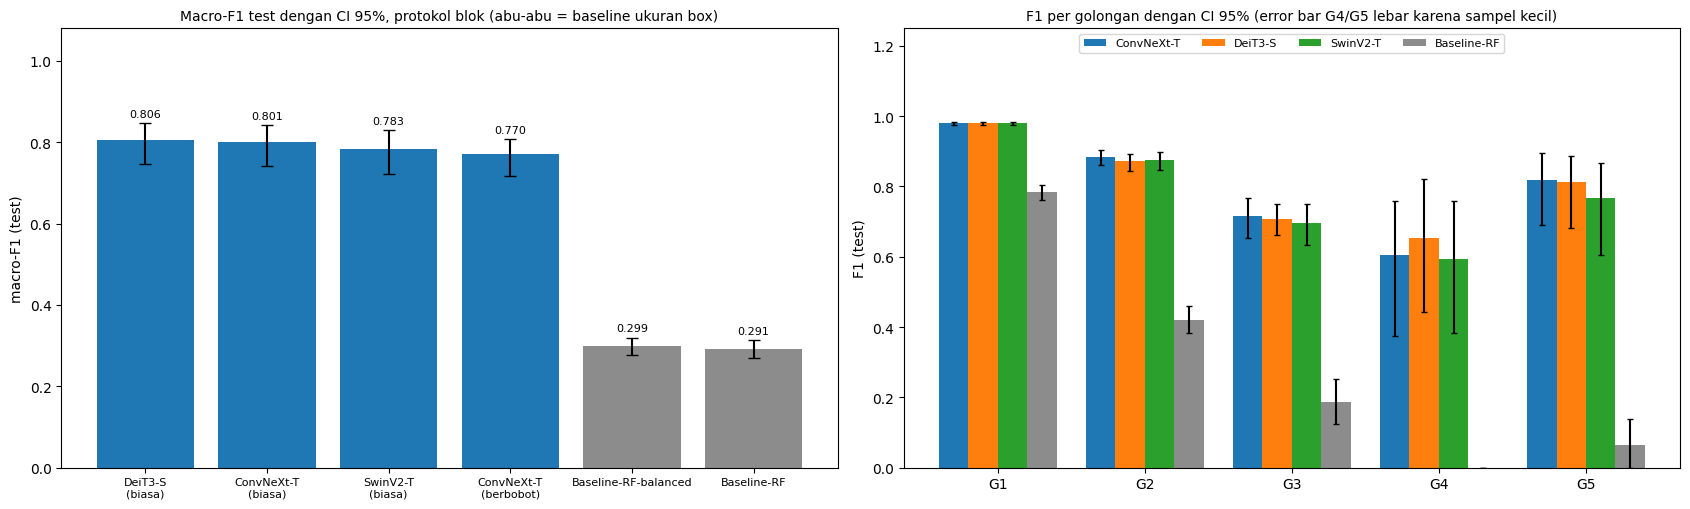


PROTOKOL: resmi  (pembanding)


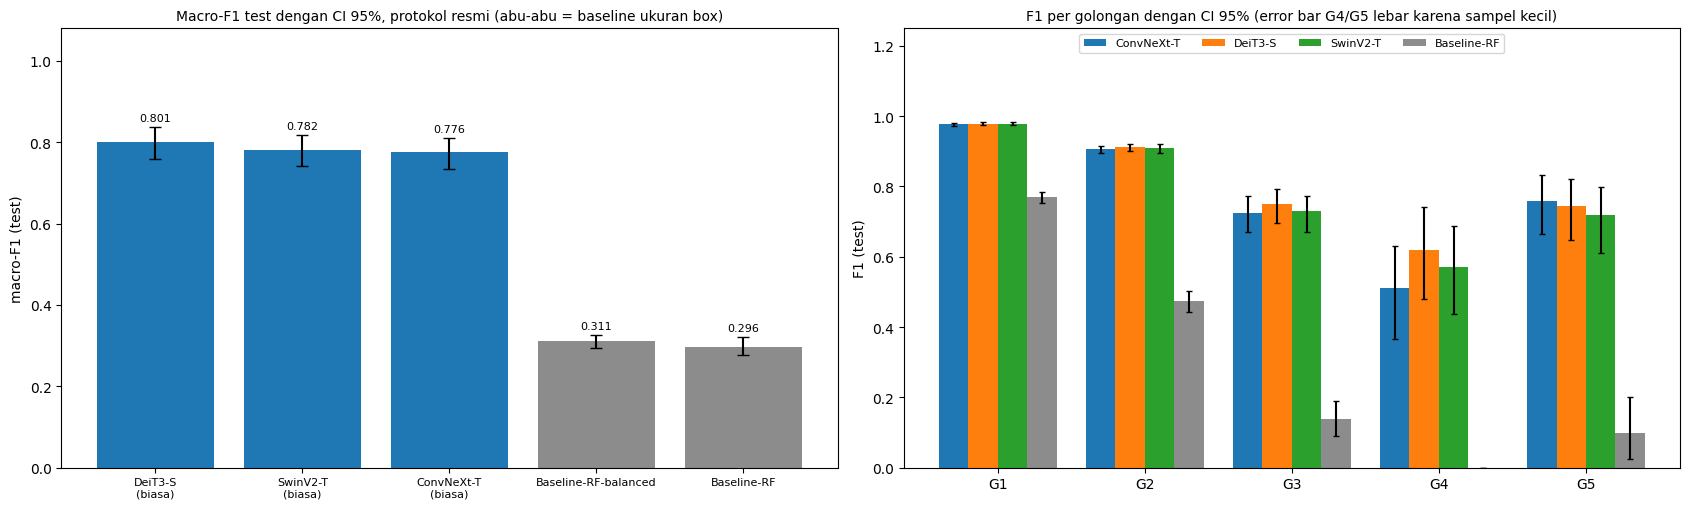

In [23]:
def grafik_hasil(A):
    t = A["ci_tab"]; yv = t["macro-F1 test"].values
    labels = [f"{r['model']}\n({r['loss']})" if r["loss"] != "-" else r["model"] for _, r in t.iterrows()]
    err = [np.clip(yv - t["CI95 bawah"].values, 0, None), np.clip(t["CI95 atas"].values - yv, 0, None)]
    cols = ["#8c8c8c" if n.startswith("Baseline") else "#1f77b4" for n in t["model"]]
    fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
    axes[0].bar(range(len(t)), yv, yerr=err, capsize=4, color=cols)
    axes[0].set_xticks(range(len(t))); axes[0].set_xticklabels(labels, fontsize=8)
    axes[0].set_ylabel("macro-F1 (test)"); axes[0].set_ylim(0, 1.08)
    axes[0].set_title(f"Macro-F1 test dengan CI 95%, protokol {A['sc']} (abu-abu = baseline ukuran box)", fontsize=10)
    for i, (v, hi) in enumerate(zip(yv, t["CI95 atas"].values)):
        axes[0].text(i, hi + 0.015, f"{v:.3f}", ha="center", fontsize=8)
    keys = [k for k in A["P"] if k[1] == "biasa"] + [("Baseline-RF", "-")]
    w = 0.8 / len(keys)
    for n_, k in enumerate(keys):
        pcm = np.mean([f1_vec(A["yte"], pr) for pr in A["P"][k]], axis=0)
        cis = np.array([ci(A["BOOT"][k][:, c]) for c in range(K)])
        axes[1].bar(np.arange(K) + n_ * w, pcm, w, yerr=[np.clip(pcm - cis[:, 0], 0, None), np.clip(cis[:, 1] - pcm, 0, None)], capsize=2,
                    label=k[0], color="#8c8c8c" if k[0].startswith("Baseline") else None)
    axes[1].set_xticks(np.arange(K) + 0.4 - w / 2); axes[1].set_xticklabels(KLS)
    axes[1].set_ylabel("F1 (test)"); axes[1].set_ylim(0, 1.25); axes[1].legend(fontsize=8, ncol=4, loc="upper center")
    axes[1].set_title("F1 per golongan dengan CI 95% (error bar G4/G5 lebar karena sampel kecil)", fontsize=10)
    plt.tight_layout(); plt.savefig(A["out"] / "hasil_utama.png", dpi=110); plt.show()

for A in ANALISIS.values():
    judul(A); grafik_hasil(A)

### 12f. Galeri salah prediksi
Model terbaik menurut val, loss biasa, seed pertama. Baris: tiga pasangan golongan yang paling sering tertukar; satu pasangan yang melibatkan golongan langka (G4/G5); dan salah prediksi pada crop **besar** (≥ 64 px), karena kesalahan pada crop besar yang jelas bisa berarti ambiguitas atau *noise* label, bukan keterbatasan resolusi.

**Cara membaca:** apakah kesalahan terjadi pada crop sangat kecil/buram (batas data), kendaraan terpotong, gandar tertutup, atau label yang meragukan, bukan sekadar "model kurang bagus". Catat contoh untuk laporan.


PROTOKOL: blok  (UTAMA)


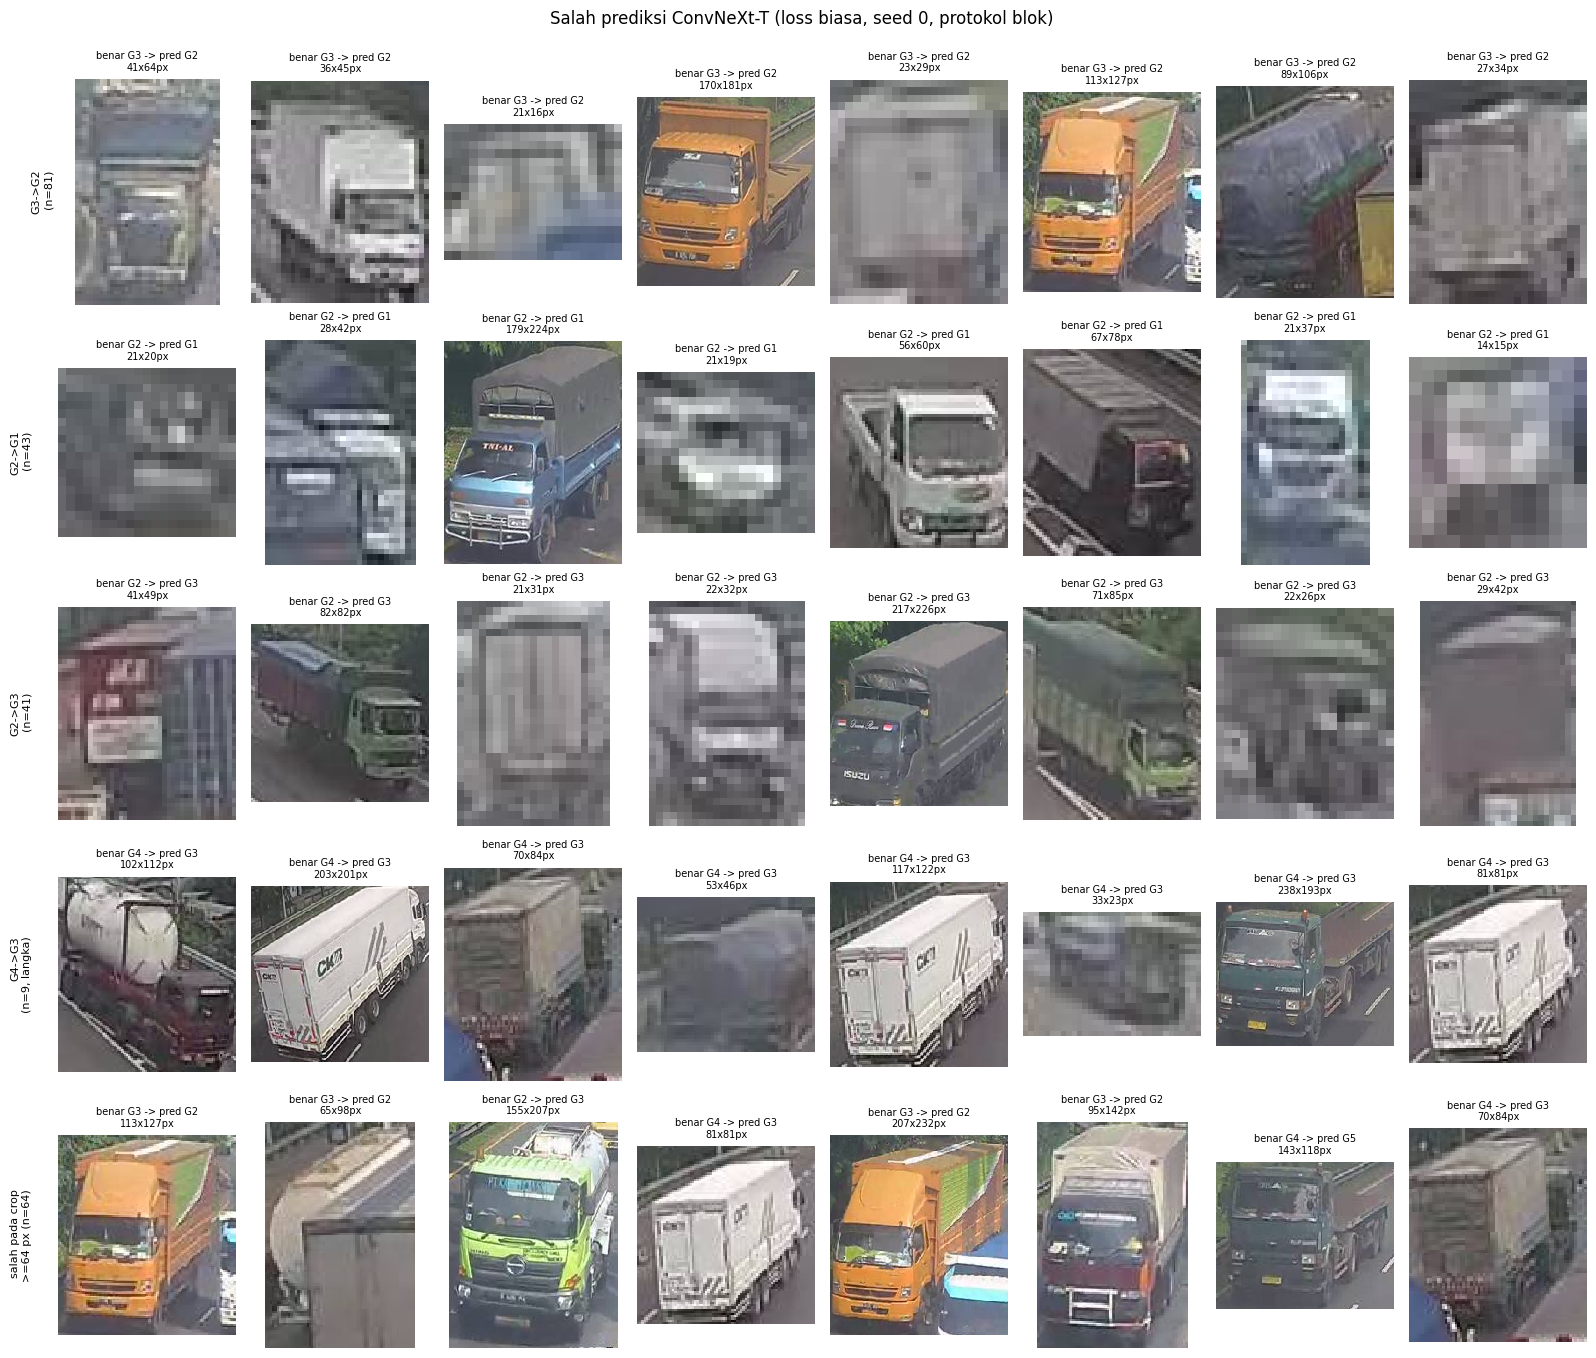


PROTOKOL: resmi  (pembanding)


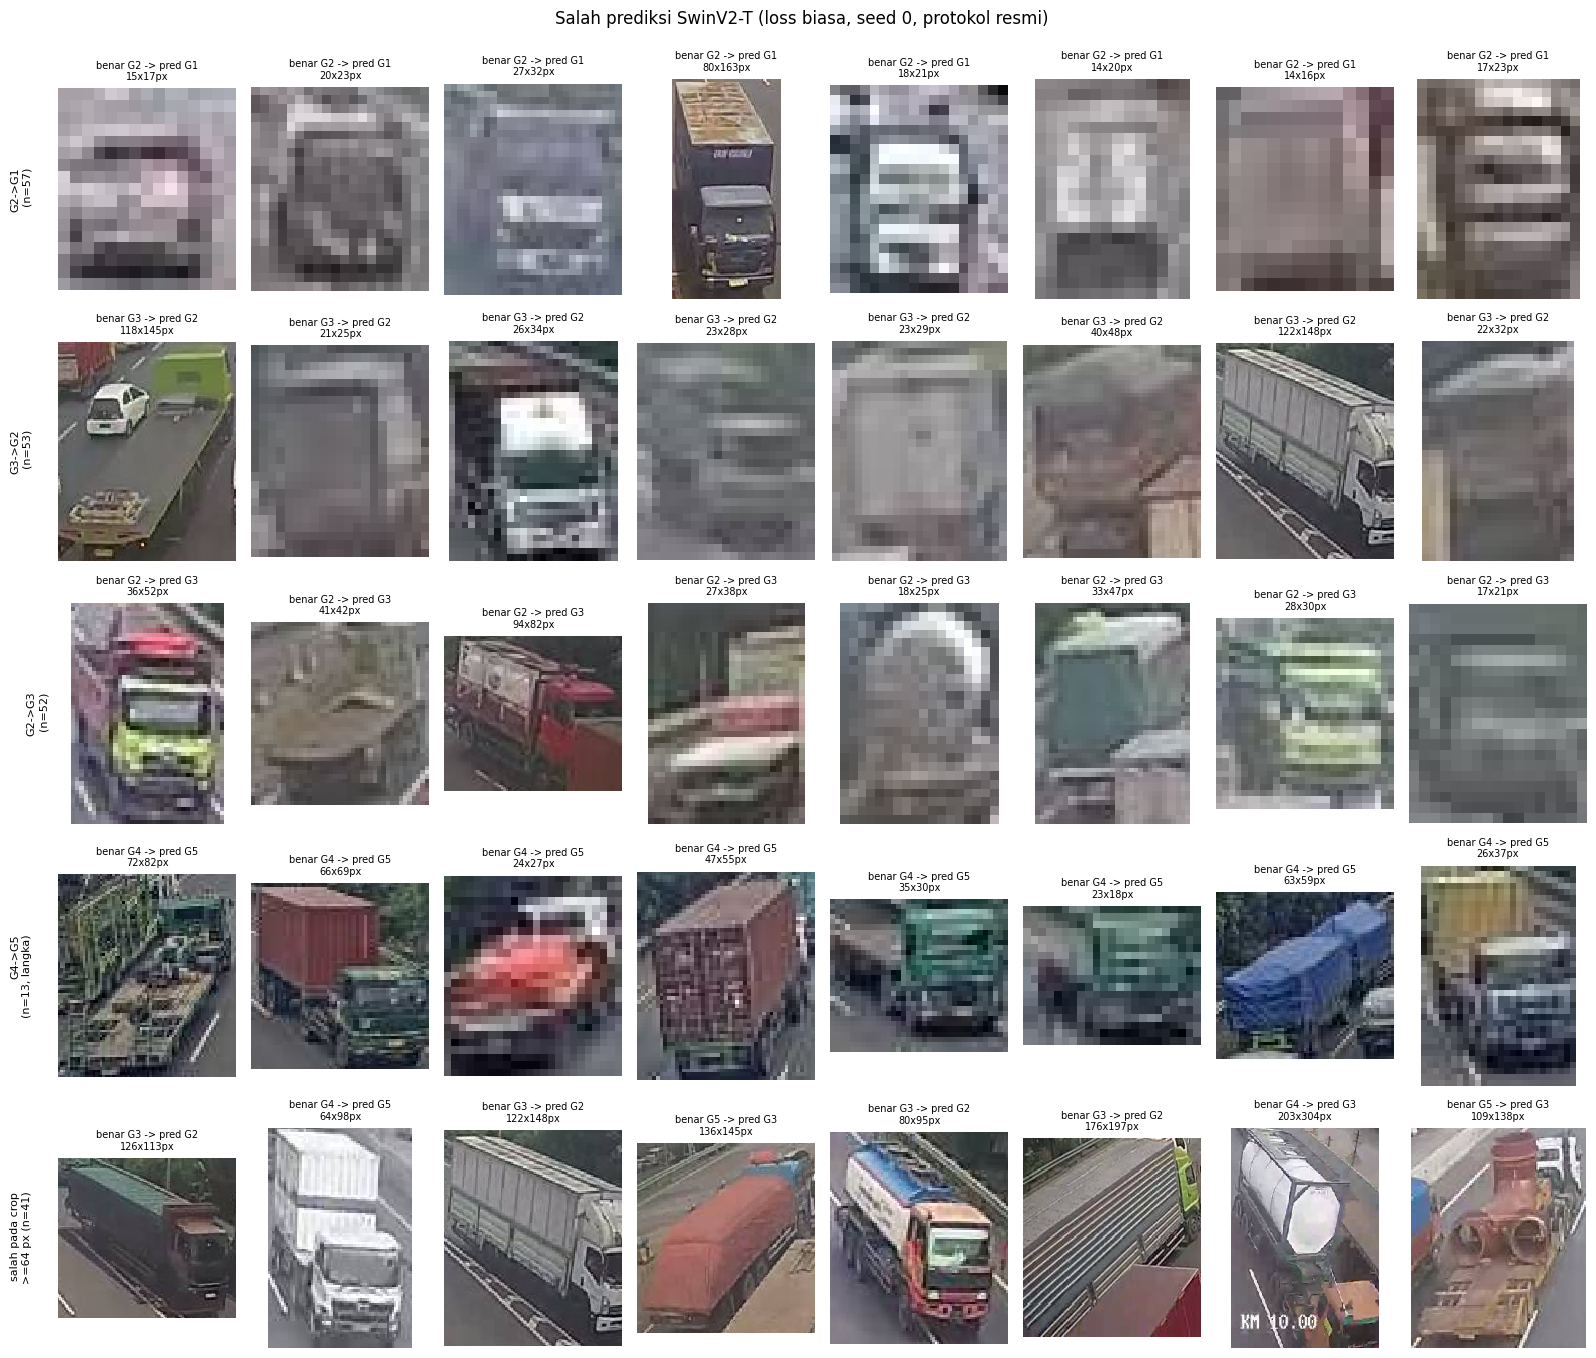

In [24]:
from collections import Counter

def galeri(A):
    key = (A["best"], "biasa"); pr0 = A["P"][key][0]; yte, te = A["yte"], A["te"]
    wrong = np.where(pr0 != yte)[0]
    if len(wrong) == 0:
        print("Tidak ada salah prediksi pada seed ini."); return
    cnt_pairs = Counter(zip(yte[wrong].tolist(), pr0[wrong].tolist())).most_common()
    spec = [((t, p), c, f"G{t + 1}->G{p + 1}\n(n={c})") for (t, p), c in cnt_pairs[:3]]
    rare = next((((t, p), c) for (t, p), c in cnt_pairs[3:] if max(t, p) >= 3), None)
    if rare: spec.append((rare[0], rare[1], f"G{rare[0][0] + 1}->G{rare[0][1] + 1}\n(n={rare[1]}, langka)"))
    big = wrong[te["short"].values[wrong] >= 64]
    rng_g = np.random.default_rng(SEED); rows = []
    for (t, p), c, lab_ in spec:
        idx = wrong[(yte[wrong] == t) & (pr0[wrong] == p)]
        rows.append((lab_, rng_g.choice(idx, size=min(8, len(idx)), replace=False)))
    if len(big): rows.append((f"salah pada crop\n>=64 px (n={len(big)})", rng_g.choice(big, size=min(8, len(big)), replace=False)))
    fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.6 * len(rows) + 0.6), squeeze=False)
    for r_, (lab_, pick) in enumerate(rows):
        for c_ in range(8):
            ax = axes[r_, c_]; ax.axis("off")
            if c_ < len(pick):
                row = te.iloc[pick[c_]]
                ax.imshow(Image.open(CROPS / row.path), interpolation="nearest")
                ax.set_title(f"benar G{yte[pick[c_]] + 1} -> pred G{pr0[pick[c_]] + 1}\n{row.pw}x{row.ph}px", fontsize=7)
        axes[r_, 0].text(-0.15, 0.5, lab_, transform=axes[r_, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    plt.suptitle(f"Salah prediksi {A['best']} (loss biasa, seed {SEEDS[0]}, protokol {A['sc']})", y=0.995)
    plt.tight_layout(); plt.savefig(A["out"] / "galeri_salah_prediksi.png", dpi=110); plt.show()

for A in ANALISIS.values():
    judul(A); galeri(A)

### 12g. Akurasi vs biaya komputasi (latensi inferensi)
Latensi per gambar (batch 64 crop test, mixed precision di GPU) dan jumlah parameter, terhadap macro-F1 protokol utama. **Cara membaca:** model di kiri-atas lebih cepat dan lebih akurat. Latensi diukur tanpa pra-pemrosesan dan hanya indikatif; hasilnya bergantung pada GPU yang dialokasikan Colab.

     model  params_M  input_px  ms_per_gambar  macroF1_test
ConvNeXt-T      27.8       224          1.573         0.801
   DeiT3-S      21.7       224          1.029         0.806
  SwinV2-T      27.6       256          3.654         0.783


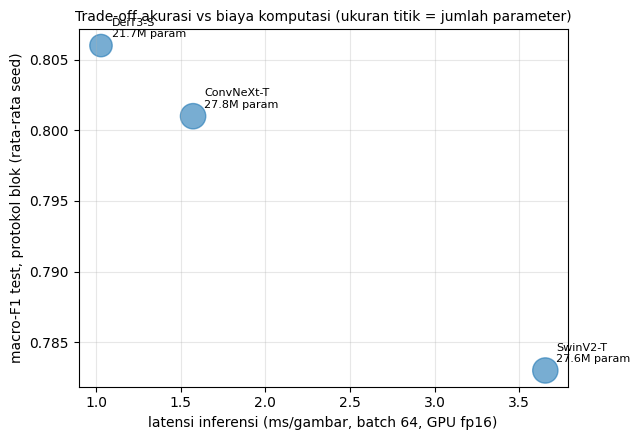

In [25]:
def latensi(A):
    ix_ = D[UTAMA]["ix_t"]["test"][:64]; xb_t = X_all[ix_]
    lat = []
    for mkey, cfg_ in MODELS.items():
        mdl = timm.create_model(cfg_["name"], pretrained=False, num_classes=5).to(dev).eval()      # bobot tidak memengaruhi latensi
        size_, mean_, std_ = model_cfg(mdl)
        with torch.no_grad():
            x_ = prep(xb_t, size_, mean_, std_, False)
            for _ in range(3):
                with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp): mdl(x_)
            if use_amp: torch.cuda.synchronize()
            t0_ = time.time()
            for _ in range(10):
                with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_amp): mdl(x_)
            if use_amp: torch.cuda.synchronize()
        ms_ = (time.time() - t0_) / 10 / len(x_) * 1000
        Rr = A["R"]; f1_ = Rr[(Rr.model == mkey) & (Rr["loss"] == "biasa")].test_f1.mean()
        lat.append(dict(model=mkey, params_M=round(sum(p.numel() for p in mdl.parameters()) / 1e6, 1), input_px=size_,
                        ms_per_gambar=round(ms_, 3), macroF1_test=round(float(f1_), 3)))
        del mdl
        if use_amp: torch.cuda.empty_cache()
    lat = pd.DataFrame(lat); print(lat.to_string(index=False)); lat.to_csv(OUT / "akurasi_vs_latensi.csv", index=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.scatter(lat.ms_per_gambar, lat.macroF1_test, s=lat.params_M * 12, alpha=.6)
    for _, r in lat.iterrows():
        ax.annotate(f"{r['model']}\n{r['params_M']}M param", (r.ms_per_gambar, r.macroF1_test), textcoords="offset points", xytext=(8, 6), fontsize=8)
    ax.set_xlabel(f"latensi inferensi (ms/gambar, batch {len(x_)}, {'GPU fp16' if use_amp else 'CPU'})"); ax.set_ylabel(f"macro-F1 test, protokol {A['sc']} (rata-rata seed)")
    ax.set_title("Trade-off akurasi vs biaya komputasi (ukuran titik = jumlah parameter)", fontsize=10); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT / "akurasi_vs_latensi.png", dpi=110); plt.show()
    return lat

LAT = latensi(ANALISIS[UTAMA])

### 12h. Dampak kebocoran temporal: split resmi vs split blok
Membandingkan macro-F1 test tiap model pada dua protokol. **Perhatikan:** test set kedua protokol **berbeda** (gambar berbeda), jadi selisih tidak seluruhnya akibat kebocoran; sebagian bisa berasal dari komposisi test. Karena itu **baseline ukuran box (tanpa piksel) dipakai sebagai kontrol**: jika baseline hampir tidak berubah sementara model turun nyata pada split blok, itu indikasi kuat bahwa penurunan berasal dari hilangnya kebocoran, bukan perbedaan komposisi.

      model  macro-F1 resmi       CI resmi  macro-F1 blok        CI blok  selisih (resmi - blok)
 ConvNeXt-T           0.776 [0.735, 0.811]          0.801 [0.741, 0.842]                  -0.025
    DeiT3-S           0.801 [0.759, 0.838]          0.806 [0.747, 0.847]                  -0.005
   SwinV2-T           0.782 [0.741, 0.818]          0.783 [0.722, 0.830]                  -0.001
Baseline-RF           0.296 [0.276, 0.321]          0.291 [0.270, 0.314]                   0.005


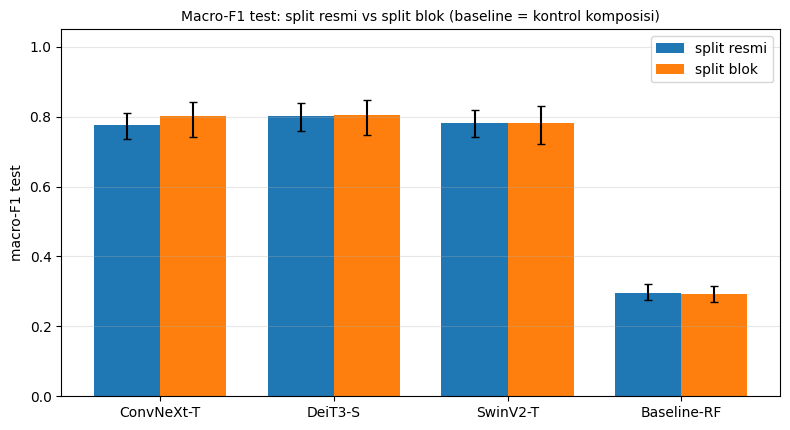

In [26]:
def bandingkan_protokol():
    if not {"blok", "resmi"} <= set(ANALISIS):
        print("Perbandingan protokol dilewati: hasil kedua protokol belum lengkap."); return None
    keys = [(mk, "biasa") for mk in MODELS] + [("Baseline-RF", "-")]
    rows, vals = [], {}
    for key in keys:
        r = {}
        for sc in ("resmi", "blok"):
            A = ANALISIS[sc]; pt = float(np.mean([f1_vec(A["yte"], pr).mean() for pr in A["P"][key]])); lo, hi = ci(A["BOOT"][key].mean(1))
            r[sc] = (pt, lo, hi)
        vals[key] = r
        rows.append({"model": key[0], "macro-F1 resmi": round(r["resmi"][0], 3), "CI resmi": f"[{r['resmi'][1]:.3f}, {r['resmi'][2]:.3f}]",
                     "macro-F1 blok": round(r["blok"][0], 3), "CI blok": f"[{r['blok'][1]:.3f}, {r['blok'][2]:.3f}]",
                     "selisih (resmi - blok)": round(r["resmi"][0] - r["blok"][0], 3)})
    tab = pd.DataFrame(rows); print(tab.to_string(index=False)); tab.to_csv(OUT / "dampak_kebocoran.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4.4)); w = 0.38
    for n_, sc in enumerate(("resmi", "blok")):
        y_ = np.array([vals[k][sc][0] for k in keys]); lo_ = np.array([vals[k][sc][1] for k in keys]); hi_ = np.array([vals[k][sc][2] for k in keys])
        ax.bar(np.arange(len(keys)) + n_ * w, y_, w, yerr=[np.clip(y_ - lo_, 0, None), np.clip(hi_ - y_, 0, None)], capsize=3, label=f"split {sc}")
    ax.set_xticks(np.arange(len(keys)) + w / 2); ax.set_xticklabels([k[0] for k in keys]); ax.set_ylabel("macro-F1 test"); ax.set_ylim(0, 1.05); ax.legend()
    ax.set_title("Macro-F1 test: split resmi vs split blok (baseline = kontrol komposisi)", fontsize=10); ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.savefig(OUT / "dampak_kebocoran.png", dpi=110); plt.show()
    return tab, vals

BAND = bandingkan_protokol()

## 13. Interpretasi
Sel berikut **menulis ringkasan temuan dari angka di atas** (otomatis, deskriptif, tanpa klaim sebab-akibat). Gunakan sebagai bahan, lalu **tulis interpretasi Anda sendiri** di sel Markdown di bawahnya. Penguji akan menanyakan alasan di balik angka, bukan angkanya.

Catatan penting: **model terbaik menurut val** (dipakai untuk Fase 2, confusion matrix, galeri) ditentukan sebelum melihat test; **peringkat test** bisa berbeda, dan jika selisihnya tidak nyata (CI mencakup 0), keduanya sama-sama sah. Jelaskan ini di laporan.

In [27]:
def fmt(a): return f"{a:.3f}"

def ringkasan(A):
    L = []
    mods = A["ci_tab"][(A["ci_tab"]["loss"] == "biasa")].reset_index(drop=True)
    L.append("1) PERINGKAT (macro-F1 test, loss biasa): " + "; ".join(
        f"{r['model']} {fmt(r['macro-F1 test'])} [CI {fmt(r['CI95 bawah'])}-{fmt(r['CI95 atas'])}]" for _, r in mods.iterrows())
        + f". Model terbaik menurut VAL (dipakai Fase 2, confusion matrix, galeri): {A['best']}.")
    for _, r in A["diff_tab"].iterrows():
        if r["dapat dibedakan?"] == "ya":
            if r["selisih A-B"] > 0:
                w, l, dl, dh = r.A, r.B, r["CI bawah"], r["CI atas"]
            else:
                w, l, dl, dh = r.B, r.A, -r["CI atas"], -r["CI bawah"]        # balik tanda agar CI berlaku untuk (unggul - kalah)
            L.append(f"2) {w} lebih tinggi dari {l} sebesar {abs(r['selisih A-B']):.3f} macro-F1 (CI95 selisih {dl:.3f} s.d. {dh:.3f}, tidak mencakup 0).")
        else:
            L.append(f"2) {r.A} vs {r.B}: selisih {r['selisih A-B']:.3f} (CI95 {r['CI bawah']:.3f} s.d. {r['CI atas']:.3f}) mencakup 0, "
                     f"jadi pada test set ini kedua model tidak dapat dibedakan.")
    bt = A["ci_tab"][A["ci_tab"].model.str.startswith("Baseline")]["macro-F1 test"].max()
    top = mods.iloc[0]
    d_base = A["BOOT"][(top["model"], "biasa")].mean(1) - A["BOOT"][("Baseline-RF", "-")].mean(1); lo, hi = ci(d_base)
    L.append(f"3) BASELINE ukuran box: macro-F1 test terbaik {bt:.3f}. Model peringkat test teratas ({top['model']}) selisihnya terhadap Baseline-RF {d_base.mean():.3f} "
             f"(CI95 {lo:.3f} s.d. {hi:.3f}); " + ("model melampaui baseline secara meyakinkan." if lo > 0 else "belum terbukti melampaui baseline ukuran box."))
    f1c = [top[f"F1 G{i}"] for i in range(1, 6)]
    L.append(f"4) PER GOLONGAN ({top['model']}): F1 = " + ", ".join(f"G{i+1} {v:.2f}" for i, v in enumerate(f1c)) + f". Terendah: G{int(np.argmin(f1c)) + 1}. "
             f"Jumlah crop test G4={int((A['yte'] == 3).sum())}, G5={int((A['yte'] == 4).sum())}, sehingga F1 kedua golongan ini berinterval lebar.")
    cm = conf(A, (A["best"], "biasa")); off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
    L.append(f"5) KESALAHAN TERBESAR ({A['best']}, loss biasa, dijumlahkan {len(SEEDS)} seed): G{i+1} diprediksi sebagai G{j+1} sebanyak {int(off[i, j])} kali "
             f"({off[i, j] / cm[i].sum() * 100:.1f}% dari G{i+1}).")
    rec6 = A["REC"][A["best"]]
    f_ = lambda x: f"n<{N_MIN}" if pd.isna(x) else f"{x:.2f}"
    L.append(f"6) UKURAN CROP (recall per golongan, {A['best']}, loss biasa): " + "; ".join(f"{g}: " + ", ".join(f"{l} {f_(rec6.loc[g, l])}" for l in labs) for g in ("G2", "G3"))
             + f". Crop {labs[0]} terdiri dari {A['nmat'].loc[1, labs[0]] / max(A['nmat'][labs[0]].sum(), 1) * 100:.0f}% G1, jadi akurasi total per ukuran tidak dipakai. "
             f"G4/G5 tidak ditafsirkan per rentang karena n kecil.")
    if (A["best"], "berbobot") in A["P"]:
        b_ = A["best"]; dw = A["BOOT"][(b_, "berbobot")].mean(1) - A["BOOT"][(b_, "biasa")].mean(1); lo, hi = ci(dw)
        rb = np.mean([recall_vec(A["yte"], pr) for pr in A["P"][(b_, "biasa")]], axis=0)
        rw = np.mean([recall_vec(A["yte"], pr) for pr in A["P"][(b_, "berbobot")]], axis=0)
        L.append(f"7) PEMBOBOTAN KELAS ({b_}): macro-F1 berbobot - biasa = {dw.mean():+.3f} (CI95 {lo:+.3f} s.d. {hi:+.3f}); "
                 + ("CI mencakup 0 -> efek tidak dapat dibedakan dari kebetulan. " if lo <= 0 <= hi else ("berbobot lebih baik. " if lo > 0 else "berbobot lebih buruk. "))
                 + f"Recall G4: {rb[3]:.2f} -> {rw[3]:.2f}; G5: {rb[4]:.2f} -> {rw[4]:.2f}.")
    notes = []
    for mk, d in A["R"][A["R"]["loss"] == "biasa"].groupby("model"):
        n_last = int((d.best_epoch == EPOCHS).sum())
        if n_last: notes.append(f"{mk} ({n_last}/{len(d)} run)")
    L.append("8) KONVERGENSI: " + ("epoch terbaik = epoch terakhir pada " + ", ".join(notes) + f"; kemungkinan belum konvergen penuh pada anggaran {EPOCHS} epoch (keterbatasan, tulis di laporan)."
                                   if notes else f"semua run mencapai epoch terbaik sebelum epoch terakhir ({EPOCHS})."))
    A["L"] = L
    return L

for A in ANALISIS.values():
    L = ringkasan(A)
    print("\n" + "=" * 90); print(f"RINGKASAN OTOMATIS, protokol {A['sc']}" + (" (UTAMA)" if A["sc"] == UTAMA else " (pembanding)")); print("=" * 90)
    for s in L: print(s + "\n")

L_BAND = []
if BAND is not None:
    tab_b, vals_b = BAND
    mm = [k for k in vals_b if k[0] != "Baseline-RF"]
    a_ = np.mean([vals_b[k]["resmi"][0] for k in mm]); b_ = np.mean([vals_b[k]["blok"][0] for k in mm])
    c_, d_ = vals_b[("Baseline-RF", "-")]["resmi"][0], vals_b[("Baseline-RF", "-")]["blok"][0]
    L_BAND.append(f"9) DAMPAK KEBOCORAN: rata-rata macro-F1 3 model: split resmi {a_:.3f} vs split blok {b_:.3f} (selisih {a_ - b_:+.3f}); "
                  f"baseline ukuran box: {c_:.3f} vs {d_:.3f} (selisih {c_ - d_:+.3f}). Test set kedua protokol berbeda, jadi selisih model dibaca bersama selisih baseline (kontrol komposisi).")
    print(L_BAND[0])


RINGKASAN OTOMATIS, protokol blok (UTAMA)
1) PERINGKAT (macro-F1 test, loss biasa): DeiT3-S 0.806 [CI 0.747-0.847]; ConvNeXt-T 0.801 [CI 0.741-0.842]; SwinV2-T 0.783 [CI 0.722-0.830]. Model terbaik menurut VAL (dipakai Fase 2, confusion matrix, galeri): ConvNeXt-T.

2) ConvNeXt-T vs DeiT3-S: selisih -0.005 (CI95 -0.032 s.d. 0.026) mencakup 0, jadi pada test set ini kedua model tidak dapat dibedakan.

2) ConvNeXt-T vs SwinV2-T: selisih 0.018 (CI95 -0.004 s.d. 0.043) mencakup 0, jadi pada test set ini kedua model tidak dapat dibedakan.

2) DeiT3-S vs SwinV2-T: selisih 0.023 (CI95 -0.004 s.d. 0.056) mencakup 0, jadi pada test set ini kedua model tidak dapat dibedakan.

3) BASELINE ukuran box: macro-F1 test terbaik 0.299. Model peringkat test teratas (DeiT3-S) selisihnya terhadap Baseline-RF 0.512 (CI95 0.449 s.d. 0.564); model melampaui baseline secara meyakinkan.

4) PER GOLONGAN (DeiT3-S): F1 = G1 0.98, G2 0.87, G3 0.71, G4 0.66, G5 0.81. Terendah: G4. Jumlah crop test G4=37, G5=65, se

### Interpretasi saya (tulis sendiri, 3–5 kalimat per butir)
Gunakan ringkasan otomatis di atas sebagai bahan, **protokol blok sebagai angka utama**. Jawab dengan kata-kata Anda:

1. **Model mana yang terbaik, dan apakah selisihnya nyata?** (lihat CI selisih berpasangan; jika mencakup 0, tulis "tidak dapat dibedakan"; sebut juga perbedaan biaya komputasi dari 12g.)
2. **Seberapa jauh di atas baseline ukuran box?** Jika dekat, apa artinya bagi klaim "model mengenali golongan"?
3. **Golongan mana yang paling sulit, dan apa polanya?** (laporan per golongan, confusion matrix, galeri; hindari menyebut penyebab sebagai fakta jika tidak terbukti oleh data.)
4. **Apa kata recall per golongan per ukuran crop** tentang batas resolusi? (pakai G2 dan G3; jangan pakai akurasi total.)
5. **Apakah pembobotan kelas membantu?** Lihat macro-F1 dan recall G4/G5, dan apakah ada harga yang dibayar (presisi turun).
6. **Seberapa besar kebocoran temporal pada split resmi?** (12h; baca bersama baseline sebagai kontrol.)
7. **Keterbatasan** (tulis semuanya):
   - satu resep training tanpa tuning per model, anggaran 8 epoch tetap (periksa catatan konvergensi);
   - 3 seed; test kecil untuk G4/G5 (CI lebar);
   - protokol blok menghilangkan kebocoran antar-frame **tetapi tidak menguji generalisasi ke kamera, lokasi, atau hari lain** (semua blok berasal dari rekaman yang sama);
   - identitas kendaraan tidak dilabeli, sehingga kebocoran diukur secara tidak langsung (jarak nomor, kemiripan piksel), bukan dihitung per kendaraan;
   - prosedur anotasi label tidak dijelaskan pada halaman dataset (kualitas label tidak dinilai);
   - semua model pra-latih ImageNet-1k *supervised*; hasil bisa berbeda untuk pra-latih lain.

*(Tulis jawaban Anda di sini, atau salin ke laporan.)*

## 14. Pencatatan lingkungan, ekspor, dan kerangka laporan
Semua tabel dan gambar sudah tersimpan di folder proyek (`OUT`): berkas umum di folder utama, berkas per protokol di `blok/` dan `resmi/`. Sel di bawah mencatat **versi perangkat lunak dan konfigurasi** (reproduktibilitas), menulis CSV akhir, dan mencetak blok **RINGKASAN** yang bisa disalin ke laporan atau dikirim untuk ditinjau.

### Kerangka laporan (publikasi website) dan slide 10 menit
| Bagian laporan | Sumber di notebook | Slide (menit) |
|---|---|---|
| Pendahuluan: masalah golongan tol, data timpang, kebocoran temporal pada split resmi | Bagian 3 | 1 (1') |
| Tinjauan pustaka: InaTRC, saLFIA, ConvNeXt, DeiT III, Swin V2, studi golongan tol sebelumnya | referensi terverifikasi | 2 (1') |
| Data: 3.250 gambar, 34.408 box, crop per box, split blok | Bagian 3–5 | 3 (1') |
| Metode: fine-tune 3 model, resep sama, pemilihan epoch di val, 3 seed, dua protokol | Bagian 6–10 | 4–5 (2') |
| Hasil: tabel macro-F1 ± std, CI, grafik hasil, kurva belajar, latensi | Bagian 11–12 | 6 (2') |
| Analisis: confusion matrix, ukuran crop, pembobotan kelas, dampak kebocoran | Bagian 12–13 | 7 (2') |
| Keterbatasan dan kesimpulan | Bagian 13 | 8 (1') |

In [28]:
def _pcfg(n):
    try:
        return {k: str(v) for k, v in timm.get_pretrained_cfg(n).to_dict().items() if k in ("hf_hub_id", "tag", "architecture", "license", "paper_name", "paper_ids")}
    except Exception as e:
        return {"error": str(e)[:100]}
Rall = results_df()
ep_per_run = {r["tag"]: len(r["history"]) for _, r in Rall.iterrows()}
env = dict(
    tanggal=datetime.datetime.now().isoformat(timespec="seconds"), versi_notebook=NOTEBOOK_VERSI,
    python=platform.python_version(), torch=torch.__version__, torch_cuda=torch.version.cuda, timm=timm.__version__,
    sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__,
    perangkat=(torch.cuda.get_device_name(0) if use_amp else "cpu"),
    konfigurasi=dict(EPOCHS=EPOCHS, SEEDS=SEEDS, BATCH=BATCH, LR=LR, WD=WD, PAD_FRAC=PAD_FRAC, MIN_SIDE=MIN_SIDE, SEED=SEED, DEBUG=DEBUG, R_STORE=R_STORE,
                     PROTOKOL=PROTOKOL, BLOCK_IMG=BLOCK_IMG, BUFFER_IMG=BUFFER_IMG, SPLIT_SEED=SPLIT_SEED, N_TRIAL_SPLIT=N_TRIAL_SPLIT,
                     BOOT_B=BOOT_B, BOOT_FRAMES=BOOT_FRAMES, RUN_AB=RUN_AB),
    data=dict(box_total=len(boxes), crop_total=len(m), gambar_dibuang_blok=int((img_tab.split_blok == "dibuang").sum()),
              per_protokol={sc: dict(train=len(D[sc]["ix"]["train"]), val=len(D[sc]["ix"]["val"]), test=len(D[sc]["ix"]["test"]),
                                     bobot_kelas=[round(float(x), 3) for x in D[sc]["class_w"].cpu().numpy()]) for sc in PROTOKOL}),
    audit_kebocoran=AUDIT,
    model={k: dict(timm_name=v["name"], **_pcfg(v["name"])) for k, v in MODELS.items()},
    jumlah_run={sc: int((Rall.scheme == sc).sum()) for sc in PROTOKOL}, epoch_per_run=ep_per_run,
    sumber_dataset="InaTRC, Mendeley Data V1, DOI 10.17632/kddgphck3b.1 (CC BY 4.0), terbit 22 April 2025",
)
(OUT / "lingkungan.json").write_text(json.dumps(env, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: v for k, v in env.items() if k not in ("epoch_per_run", "model")}, indent=2, ensure_ascii=False))
print("Model:", json.dumps(env["model"], ensure_ascii=False))
if set(ep_per_run.values()) != {EPOCHS}:
    print("\n!!! PERINGATAN PROTOKOL: jumlah epoch antar run tidak seragam", sorted(set(ep_per_run.values())), "(EPOCHS saat ini =", EPOCHS, ").")
else:
    print(f"\nProtokol seragam: semua {len(Rall)} run memakai {EPOCHS} epoch.")

{
  "tanggal": "2026-11-15T18:05:15",
  "versi_notebook": "v3",
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torch_cuda": "13.0",
  "timm": "1.0.31",
  "sklearn": "1.6.1",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "perangkat": "Tesla T4",
  "konfigurasi": {
    "EPOCHS": 8,
    "SEEDS": [
      0,
      1,
      2
    ],
    "BATCH": 64,
    "LR": 0.0001,
    "WD": 0.05,
    "PAD_FRAC": 0.0,
    "MIN_SIDE": 0,
    "SEED": 42,
    "DEBUG": false,
    "R_STORE": 128,
    "PROTOKOL": [
      "blok",
      "resmi"
    ],
    "BLOCK_IMG": 40,
    "BUFFER_IMG": 10,
    "SPLIT_SEED": 2026,
    "N_TRIAL_SPLIT": 20000,
    "BOOT_B": 1000,
    "BOOT_FRAMES": 10,
    "RUN_AB": false
  },
  "data": {
    "box_total": 34408,
    "crop_total": 34408,
    "gambar_dibuang_blok": 290,
    "per_protokol": {
      "blok": {
        "train": 24597,
        "val": 3504,
        "test": 3316,
        "bobot_kelas": [
          0.337,
          0.668,
          2.619,
          16.453,
          10.

In [29]:
for sc, A in ANALISIS.items():
    A["summary"].to_csv(A["out"] / "ringkasan_hasil.csv", index=False)
    A["pc_tab"].to_csv(A["out"] / "f1_per_golongan.csv")
    A["ci_tab"].to_csv(A["out"] / "macroF1_test_ci.csv", index=False)
    A["diff_tab"].to_csv(A["out"] / "selisih_berpasangan.csv", index=False)
    A["cr_tab"].to_csv(A["out"] / "laporan_per_golongan.csv", index=False)
    (A["out"] / "interpretasi_otomatis.txt").write_text("\n\n".join(A["L"] + (L_BAND if sc == UTAMA else [])), encoding="utf-8")
for sc in PROTOKOL:
    BASE_VAL[sc].to_csv(OUT / f"baseline_val_{sc}.csv")
m.drop(columns=["short"]).to_csv(OUT / "manifest.csv", index=False)
print("Tersimpan di", OUT, ":", sorted(p.name for p in OUT.iterdir()))

print("\n" + "=" * 90); print("RINGKASAN (salin blok ini)"); print("=" * 90)
print(f"VERSI={NOTEBOOK_VERSI} PROTOKOL={PROTOKOL} MIN_SIDE={MIN_SIDE} PAD_FRAC={PAD_FRAC} EPOCHS={EPOCHS} SEEDS={SEEDS} BATCH={BATCH} LR={LR} DEBUG={DEBUG}")
print(f"BLOCK_IMG={BLOCK_IMG} BUFFER_IMG={BUFFER_IMG} SPLIT_SEED={SPLIT_SEED} BOOT_FRAMES={BOOT_FRAMES}")
print("Audit kebocoran:", json.dumps(AUDIT))
for sc, A in ANALISIS.items():
    print("\n" + "-" * 90); print(f"PROTOKOL {sc}" + (" (UTAMA)" if sc == UTAMA else " (pembanding)") + f": crop train/val/test = {len(D[sc]['ix']['train'])}/{len(D[sc]['ix']['val'])}/{len(D[sc]['ix']['test'])}")
    print(BASE_VAL[sc].to_string()); print(); print(A["summary"].to_string(index=False)); print()
    print(A["ci_tab"].to_string(index=False)); print(); print(A["diff_tab"].to_string(index=False)); print()
    print(f"Recall per golongan per ukuran crop ({A['best']}, loss biasa):"); print(A["REC"][A["best"]].round(3).to_string()); print()
    for s in A["L"]: print(s)
if BAND is not None:
    print("\n" + "-" * 90); print("DAMPAK KEBOCORAN"); print(BAND[0].to_string(index=False)); print(L_BAND[0])

Tersimpan di /content/drive/MyDrive/UNPAM/Advance Computer Vision/Perbandingan ConvNeXt, DeiT III, dan Swin V2 pada Klasifikasi Golongan Kendaraan Gerbang Tol pada Dataset InaTRC - Ahmad Muzanni_251012000041 : ['UAS_ACV_InaTRC-V1.ipynb', 'akurasi_vs_latensi.csv', 'akurasi_vs_latensi.png', 'audit_kebocoran.json', 'audit_kebocoran_frame.png', 'baseline_val_blok.csv', 'baseline_val_resmi.csv', 'blok', 'dampak_kebocoran.csv', 'dampak_kebocoran.png', 'eda_distribusi_ukuran.png', 'lingkungan.json', 'manifest.csv', 'qa_grid.png', 'resmi', 'runs', 'split_blok.csv', 'split_blok_timeline.png']

RINGKASAN (salin blok ini)
VERSI=v3 PROTOKOL=['blok', 'resmi'] MIN_SIDE=0 PAD_FRAC=0.0 EPOCHS=8 SEEDS=[0, 1, 2] BATCH=64 LR=0.0001 DEBUG=False
BLOCK_IMG=40 BUFFER_IMG=10 SPLIT_SEED=2026 BOOT_FRAMES=10
Audit kebocoran: {"jarak_nomor_val_median": 1.0, "jarak_nomor_val_maks": 3, "jarak_nomor_test_median": 1.0, "jarak_nomor_test_maks": 3, "selisih_piksel_berurutan_median": 5.094135761260986, "selisih_piksel_a